# XAI Results Analysis

This notebook analyses the current framework exports and reads predictive performance from `results/uncertainty/bootstrap_metrics_long.csv`.

Run from `src/analysis/` after the XAI-extension notebooks and bootstrap script. HbA1c explanations are **in-sample** and are shown as a separate descriptive case; HbA1c is excluded from held-out predictive performance. Exported tables are written to `results/cross_dataset/`.


## Setup


In [1]:
import json
import re
import textwrap
from pathlib import Path
from textwrap import fill

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

RESULTS_DIR = Path("../../results").resolve()

DATASETS = [
    "heart",
    "stroke",
    "diabetes",
    "ckd",
    "hba1c"
]

DISPLAY_NAMES = {
    "heart": "Heart",
    "stroke": "Stroke",
    "diabetes": "Diabetes",
    "ckd": "CKD",
    "hba1c": "HbA1c (in-sample)"
}

ANALYSIS_OUT = RESULTS_DIR / "cross_dataset"

if not RESULTS_DIR.exists():
    raise FileNotFoundError(
        f"Results directory not found: {RESULTS_DIR}"
    )

missing_dataset_dirs = [
    dataset
    for dataset in DATASETS
    if not (RESULTS_DIR / dataset).is_dir()
]

if missing_dataset_dirs:
    raise FileNotFoundError(
        "Missing dataset result directories: "
        + ", ".join(missing_dataset_dirs)
    )

ANALYSIS_OUT.mkdir(parents=True, exist_ok=True)

print("Results directory:", RESULTS_DIR)
print("Analysis output:", ANALYSIS_OUT)


Results directory: C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\results
Analysis output: C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\results\cross_dataset


In [2]:
THESIS_GREEN_DARK = "#5E7D68"
THESIS_GREEN = "#7FAF8F"
THESIS_GREEN_LIGHT = "#B8CDBE"
THESIS_GREY = "#E6E6E6"

THESIS_GREEN_PALETTE = [
    THESIS_GREEN_DARK,
    THESIS_GREEN,
    THESIS_GREEN_LIGHT
]


### Shared loading and validation helpers


In [3]:
def load_metadata(dataset):
    """Load exported metadata for one dataset."""
    path = RESULTS_DIR / dataset / "bundle" / "metadata.json"

    if not path.exists():
        return {}

    with path.open("r", encoding="utf-8") as file:
        return json.load(file)


def load_global_tables(dataset):
    """Load native, permutation, and SHAP importance tables."""
    dataset_dir = RESULTS_DIR / dataset

    native = pd.read_csv(dataset_dir / "native_importance.csv")
    permutation = pd.read_csv(
        dataset_dir / "permutation_importance.csv"
    )
    shap = pd.read_csv(dataset_dir / "shap_importance.csv")

    for name, df, importance_column in [
        ("Native", native, "Importance"),
        ("Permutation", permutation, "Importance"),
        ("SHAP", shap, "MeanAbsSHAP")
    ]:
        required = {"Feature", importance_column}
        missing = required.difference(df.columns)

        if missing:
            raise ValueError(
                f"{dataset} {name} table is missing: "
                f"{sorted(missing)}"
            )

        df.drop(
            df[
                df["Feature"]
                .astype(str)
                .str.lower()
                .isin(["intercept", "const"])
            ].index,
            inplace=True
        )

    feature_sets = []
    for name, table, importance_col in [("Native", native, "Importance"), ("Permutation", permutation, "Importance"), ("SHAP", shap, "MeanAbsSHAP")]:
        if table["Feature"].isna().any() or table["Feature"].duplicated().any():
            raise ValueError(f"{dataset} {name}: missing or duplicate feature names")
        if not np.isfinite(table[importance_col].to_numpy(dtype=float)).all():
            raise ValueError(f"{dataset} {name}: non-finite importance values")
        feature_sets.append(set(table["Feature"]))
    if not all(features == feature_sets[0] for features in feature_sets):
        raise ValueError(f"{dataset}: explanation methods cover different feature sets")
    return native, permutation, shap


def load_stability_rank(dataset):
    """Load the exported stability-rank table when available."""
    path = RESULTS_DIR / dataset / "stability_rank.csv"
    return pd.read_csv(path) if path.exists() else None


def load_feature_stability(dataset):
    """Load the exported feature-stability summary when available."""
    path = RESULTS_DIR / dataset / "stability_summary.csv"
    return pd.read_csv(path) if path.exists() else None


# 1.1 Models used for the XAI extension

Model classes are read from the exported bundles. These identify the fitted models used for explanations, not the best-performing candidates in the source papers. Stroke uses the pre-specified balanced logistic regression. HbA1c uses full-cohort inference.


In [4]:
model_selection_rows = []

for dataset in DATASETS:
    metadata = load_metadata(dataset)
    model_name = metadata.get("model", "Unknown")

    if model_name == "BinaryResultsWrapper":
        model_name = "Statsmodels logistic regression"

    model_selection_rows.append({
        "Dataset": DISPLAY_NAMES[dataset],
        "XAIModel": model_name,
        "EvaluationScope": "In-sample" if dataset == "hba1c" else "Held-out",
        "PermutationScoring": metadata.get("scoring", "Unknown")
    })

model_selection_df = pd.DataFrame(model_selection_rows)
display(model_selection_df)


,Dataset,XAIModel,EvaluationScope,PermutationScoring
0,Heart,LogisticRegressionCV,Held-out,roc_auc
1,Stroke,LogisticRegression,Held-out,roc_auc
2,Diabetes,RandomForestClassifier,Held-out,roc_auc
3,CKD,RandomForestClassifier,Held-out,roc_auc
4,HbA1c (in-sample),Statsmodels logistic regression,In-sample,roc_auc


Saved: C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\images\results\predictive_performance.pdf


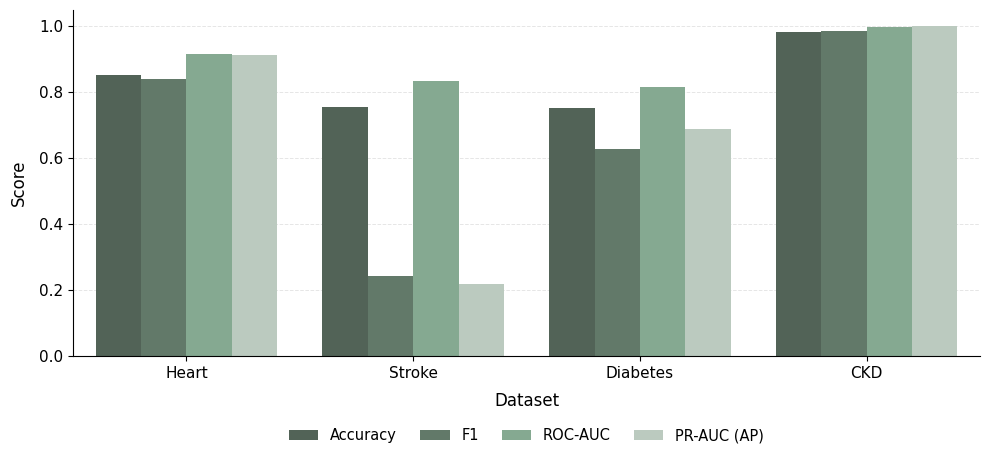

In [5]:
bootstrap_path = RESULTS_DIR / "uncertainty" / "bootstrap_metrics_long.csv"
if not bootstrap_path.is_file():
    raise FileNotFoundError("Run bootstrap_model_uncertainty.py before this notebook.")
bootstrap_df = pd.read_csv(bootstrap_path)
required = {"Dataset", "Metric", "Estimate", "CI95_Lower", "CI95_Upper"}
if not required.issubset(bootstrap_df.columns):
    raise ValueError(f"Missing bootstrap columns: {required - set(bootstrap_df.columns)}")
predictive_datasets = ["heart", "stroke", "diabetes", "ckd"]
if set(bootstrap_df["Dataset"]) != set(predictive_datasets):
    raise ValueError("Expected the four held-out datasets only; HbA1c is not eligible.")
if bootstrap_df.duplicated(["Dataset", "Metric"]).any():
    raise ValueError("Duplicate dataset/metric records in bootstrap export.")
required_metrics = {"Accuracy", "Precision", "Recall", "Specificity", "F1", "ROC_AUC", "PR_AUC"}
for dataset in predictive_datasets:
    records = bootstrap_df.loc[bootstrap_df["Dataset"] == dataset]
    if set(records["Metric"]) != required_metrics:
        raise ValueError(f"Incomplete bootstrap metrics for {dataset}")
if not np.isfinite(bootstrap_df[["Estimate", "CI95_Lower", "CI95_Upper"]].to_numpy()).all():
    raise ValueError("Bootstrap output contains non-finite values.")

performance_df = (
    bootstrap_df.pivot(index="Dataset", columns="Metric", values="Estimate")
    .reindex(predictive_datasets)[["Accuracy", "F1", "ROC_AUC", "PR_AUC"]]
    .reset_index()
)
performance_df["Dataset"] = performance_df["Dataset"].map(DISPLAY_NAMES)
# PR_AUC in the existing script is calculated as average precision.
plot_df = performance_df.melt(
    id_vars="Dataset",
    var_name="Metric",
    value_name="Value"
)

fig, ax = plt.subplots(figsize=(10, 5.2))

sns.barplot(
    data=plot_df,
    x="Dataset",
    y="Value",
    hue="Metric",
    palette=[
        "#4F6656",
        "#5E7D68",
        "#7FAF8F",
        "#B8CDBE",
    ],
    ax=ax,
)

ax.set_ylim(0, 1.05)

ax.set_xlabel(
    "Dataset",
    fontsize=12,
    labelpad=8,
)

ax.set_ylabel(
    "Score",
    fontsize=12,
    labelpad=8,
)

ax.tick_params(
    axis="both",
    labelsize=11,
)

ax.set_axisbelow(True)
ax.grid(
    axis="y",
    color="#E6E6E6",
    linestyle="--",
    linewidth=0.7,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

handles, labels = ax.get_legend_handles_labels()

label_names = {
    "PR_AUC": "PR-AUC (AP)",
    "ROC_AUC": "ROC-AUC",
}

ax.legend(
    handles,
    [label_names.get(label, label) for label in labels],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.17),
    ncol=4,
    frameon=False,
    title=None,
    fontsize=10.5,
    handlelength=2,
    columnspacing=1.6,
)

fig.tight_layout(
    rect=[0, 0.08, 1, 1]
)

FIGURE_DIR = RESULTS_DIR.parent / "images" / "results"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

figure_path = FIGURE_DIR / "predictive_performance.pdf"

fig.savefig(
    figure_path,
    bbox_inches="tight",
)

print("Saved:", figure_path)

plt.show()


Saved: C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\images\results\predictive_performance_heatmap.pdf


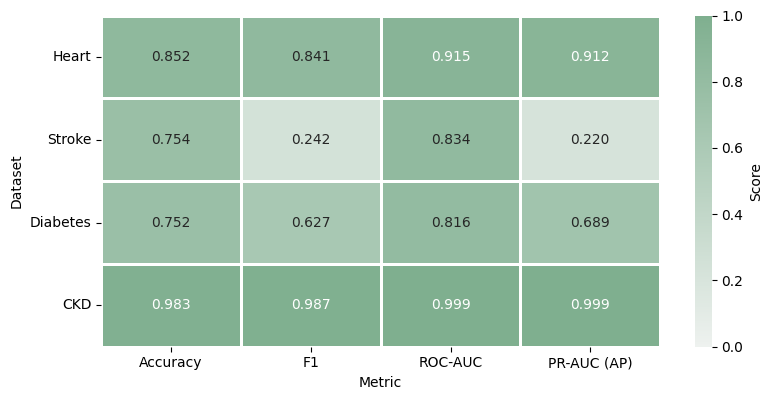

In [6]:

FIGURE_DIR = RESULTS_DIR.parent / "images" / "results"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

performance_heatmap = (
    performance_df
    .set_index("Dataset")[
        ["Accuracy", "F1", "ROC_AUC", "PR_AUC"]
    ]
    .copy()
)

performance_heatmap = performance_heatmap.rename(
    columns={
        "ROC_AUC": "ROC-AUC",
        "PR_AUC": "PR-AUC (AP)",
    }
)

fig, ax = plt.subplots(figsize=(8.2, 4.1))

sns.heatmap(
    performance_heatmap,
    annot=True,
    fmt=".3f",
    cmap=sns.light_palette(
        "#7FAF8F",
        as_cmap=True,
    ),
    vmin=0,
    vmax=1,
    linewidths=1,
    linecolor="white",
    cbar_kws={
        "label": "Score",
    },
    ax=ax,
)

ax.set_xlabel("Metric")
ax.set_ylabel("Dataset")
ax.tick_params(axis="y", rotation=0)

fig.tight_layout()

figure_path = (
    FIGURE_DIR
    / "predictive_performance_heatmap.pdf"
)

fig.savefig(
    figure_path,
    bbox_inches="tight",
)

print("Saved:", figure_path)

plt.show()


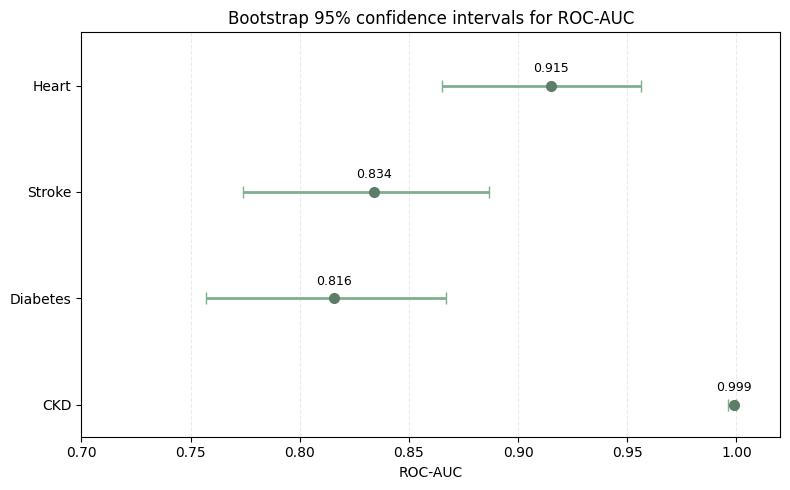

In [7]:
uncertainty_df = (
    bootstrap_df.loc[bootstrap_df["Metric"] == "ROC_AUC"]
    .set_index("Dataset").reindex(predictive_datasets)
    .rename(columns={"Estimate": "ROC_AUC", "CI95_Lower": "ROC_AUC_low", "CI95_Upper": "ROC_AUC_high"})
    .reset_index()
)
uncertainty_df["Dataset"] = uncertainty_df["Dataset"].map(DISPLAY_NAMES)

plt.figure(figsize=(8, 5))

plot_df = uncertainty_df.iloc[::-1].reset_index(drop=True)

x = plot_df["ROC_AUC"]

xerr = [
    x - plot_df["ROC_AUC_low"],
    plot_df["ROC_AUC_high"] - x
]

plt.errorbar(
    x,
    range(len(plot_df)),
    xerr=xerr,
    fmt="o",
    color="#5E7D68",
    ecolor="#7FAF8F",
    elinewidth=2,
    capsize=4,
    markersize=7
)

plt.yticks(
    range(len(plot_df)),
    plot_df["Dataset"]
)

plt.xlabel("ROC-AUC")
plt.title("Bootstrap 95% confidence intervals for ROC-AUC")
plt.xlim(0.70, 1.02)
plt.ylim(-0.3, len(plot_df) - 0.5)

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

for i, value in enumerate(plot_df["ROC_AUC"]):
    plt.text(
        value,
        i + 0.10,
        f"{value:.3f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()


# 1.2 Global XAI results per dataset

Intercept or constant terms are excluded consistently. Native, permutation, and SHAP magnitudes remain method-specific; comparisons below use feature ranks and top-feature membership. HbA1c features are Patsy design-matrix terms, including categorical contrasts and interactions.


HbA1c is an in-sample analysis of design-matrix terms; the other datasets use held-out observations. Global permutation importance uses ROC-AUC for all five configurations. Normalized magnitudes are visual summaries, not a common measure of explanatory strength.

Diabetes has exactly five features: its top-five set overlap is necessarily 100% when all methods cover those features, regardless of ranking agreement.


In [8]:
def global_rank_table(dataset):
    """Build an aligned global-importance rank table for one dataset."""
    native, permutation, shap = load_global_tables(dataset)

    native_df = native[["Feature", "Importance"]].rename(
        columns={"Importance": "NativeImportance"}
    )
    permutation_df = permutation[["Feature", "Importance"]].rename(
        columns={"Importance": "PermutationImportance"}
    )
    shap_df = shap[["Feature", "MeanAbsSHAP"]].rename(
        columns={"MeanAbsSHAP": "SHAPImportance"}
    )

    merged = (
        native_df
        .merge(permutation_df, on="Feature", how="inner")
        .merge(shap_df, on="Feature", how="inner")
    )

    if merged.empty:
        raise ValueError(
            f"{dataset}: no features are shared by all three methods"
        )

    for importance_col, rank_col in [
        ("NativeImportance", "NativeRank"),
        ("PermutationImportance", "PermutationRank"),
        ("SHAPImportance", "SHAPRank")
    ]:
        merged[rank_col] = merged[importance_col].rank(
            ascending=False,
            method="average"
        )

    rank_cols = [
        "NativeRank",
        "PermutationRank",
        "SHAPRank"
    ]
    merged["MeanRank"] = merged[rank_cols].mean(axis=1)
    merged["RankRange"] = (
        merged[rank_cols].max(axis=1)
        - merged[rank_cols].min(axis=1)
    )

    return merged.sort_values(
        ["MeanRank", "Feature"],
        ignore_index=True
    )


In [9]:
global_top5_rows = []
global_overlap_rows = []
common_feature_rows = []
all_global_rank_tables = []

for dataset in DATASETS:
    native, permutation, shap = load_global_tables(dataset)

    method_specs = {
        "Native": (native, "Importance"),
        "Permutation": (permutation, "Importance"),
        "SHAP": (shap, "MeanAbsSHAP")
    }

    top_features = {}

    for method, (df, importance_col) in method_specs.items():
        if len(df) < 5:
            raise ValueError(
                f"{dataset} {method} has fewer than five features"
            )

        top_features[method] = (
            df.nlargest(5, importance_col)["Feature"].tolist()
        )

    for rank in range(5):
        global_top5_rows.append({
            "Dataset": DISPLAY_NAMES[dataset],
            "Rank": rank + 1,
            "Native": top_features["Native"][rank],
            "Permutation": top_features["Permutation"][rank],
            "SHAP": top_features["SHAP"][rank]
        })

    native_set = set(top_features["Native"])
    permutation_set = set(top_features["Permutation"])
    shap_set = set(top_features["SHAP"])
    common = native_set & permutation_set & shap_set

    global_overlap_rows.append({
        "Dataset": DISPLAY_NAMES[dataset],
        "Native_SHAP_Top5_Overlap": len(native_set & shap_set) / 5,
        "Native_Permutation_Top5_Overlap": (
            len(native_set & permutation_set) / 5
        ),
        "SHAP_Permutation_Top5_Overlap": (
            len(shap_set & permutation_set) / 5
        ),
        "N_Common_All_Three": len(common),
        "NFeatures": len(native),
        "Top5CoversAllFeatures": len(native) == 5
    })

    common_feature_rows.append({
        "Dataset": DISPLAY_NAMES[dataset],
        "CommonTop5Features": ", ".join(sorted(common)),
        "NCommon": len(common)
    })

    rank_table = global_rank_table(dataset).copy()
    rank_table.insert(0, "Dataset", DISPLAY_NAMES[dataset])
    all_global_rank_tables.append(rank_table)

global_top5_df = pd.DataFrame(global_top5_rows)
global_overlap_df = pd.DataFrame(global_overlap_rows)
common_global_features_df = pd.DataFrame(common_feature_rows)
global_rank_all_df = pd.concat(
    all_global_rank_tables,
    ignore_index=True
)

display(global_top5_df)
display(global_overlap_df.round(3))
display(common_global_features_df)


,Dataset,Rank,Native,Permutation,SHAP
0,Heart,1,thal,thal,thal
1,Heart,2,cp,ca,cp
2,Heart,3,exang,sex,exang
3,Heart,4,thalach,thalach,thalach
4,Heart,5,ca,cp,slope
5,Stroke,1,age,age,age
6,Stroke,2,bmi_missing,avg_glucose_level,avg_glucose_level
7,Stroke,3,avg_glucose_level,bmi_missing,hypertension
8,Stroke,4,hypertension,heart_disease,bmi_missing
9,Stroke,5,heart_disease,ever_married_No,heart_disease


,Dataset,Native_SHAP_Top5_Overlap,Native_Permutation_Top5_Overlap,SHAP_Permutation_Top5_Overlap,N_Common_All_Three,NFeatures,Top5CoversAllFeatures
0,Heart,0.8,0.8,0.6,3,13,False
1,Stroke,1.0,0.8,0.8,4,7,False
2,Diabetes,1.0,1.0,1.0,5,5,True
3,CKD,1.0,0.8,0.8,4,24,False
4,HbA1c (in-sample),0.0,0.0,0.8,0,90,False


,Dataset,CommonTop5Features,NCommon
0,Heart,"cp, thal, thalach",3
1,Stroke,"age, avg_glucose_level, bmi_missing, heart_dis...",4
2,Diabetes,"Age, BMI, Glucose, Insulin, SkinThickness",5
3,CKD,"al, pcv, sc, sg",4
4,HbA1c (in-sample),,0


### 1.2.1 Global importance plots


In [10]:
def wrap_feature_label(label, width=32):
    """Wrap a feature label without splitting words."""
    return "\n".join(
        textwrap.wrap(
            str(label),
            width=width,
            break_long_words=False,
            break_on_hyphens=False
        )
    )


In [11]:
def clean_feature_label(label):
    """
    Make long feature/design-matrix labels easier to read in plots.
    Original feature names remain unchanged in the underlying data.
    """
    label = str(label)

    replacements = {
        "specialty_group[T.": "Specialty: ",
        "age_group3[T.": "Age: ",
        "discharge_group[T.": "Discharge: ",
        "admission_type_group[T.": "Admission type: ",
        "admission_source_group[T.": "Admission source: "
    }

    for old, new in replacements.items():
        label = label.replace(old, new)

    # Convert interaction separator into a clearer visual symbol
    label = label.replace("]:", " × ")

    # Remove remaining Patsy syntax
    label = label.replace("[T.", "")
    label = label.replace("]", "")

    return label


def plot_global_importance_combined(dataset, top_n=5):
    """Plot aligned global-importance results for one dataset."""

    native, permutation, shap = load_global_tables(dataset)

    # Prepare native importance.
    native = native[
        ["Feature", "Importance"]
    ].copy()

    native["Method"] = "Native"

    native = native.rename(
        columns={
            "Importance": "ImportanceValue"
        }
    )

    # Prepare permutation importance.
    permutation = permutation[
        ["Feature", "Importance"]
    ].copy()

    permutation["Method"] = "Permutation"

    permutation = permutation.rename(
        columns={
            "Importance": "ImportanceValue"
        }
    )

    # Prepare SHAP importance.
    shap = shap[
        ["Feature", "MeanAbsSHAP"]
    ].copy()

    shap["Method"] = "SHAP"

    shap = shap.rename(
        columns={
            "MeanAbsSHAP": "ImportanceValue"
        }
    )

    # Combine the three global methods.
    combined = pd.concat(
        [
            native,
            permutation,
            shap
        ],
        ignore_index=True
    )

    # Normalise importance within each method.
    # Necessary because Native, Permutation and SHAP values
    # are not on the same numerical scale.
    combined["NormalizedImportance"] = (
        combined
        .groupby("Method")["ImportanceValue"]
        .transform(
            lambda x:
                x / x.max()
                if x.max() != 0
                else 0
        )
    )

    # Calculate mean normalised importance for each feature.
    # Average across the three global methods.
    feature_summary = (
        combined
        .groupby(
            "Feature",
            as_index=False
        )
        .agg(
            MeanNormalizedImportance=(
                "NormalizedImportance",
                "mean"
            )
        )
    )

    # Select the strongest features overall.
    top_features = (
        feature_summary
        .nlargest(
            top_n,
            "MeanNormalizedImportance"
        )["Feature"]
        .tolist()
    )

    # Create the plotting table.
    plot_df = (
        combined[
            combined["Feature"].isin(top_features)
        ]
        .copy()
    )

    # Determine the display order.
    feature_order = (
        feature_summary[
            feature_summary["Feature"].isin(top_features)
        ]
        .sort_values(
            "MeanNormalizedImportance",
            ascending=False
        )["Feature"]
        .tolist()
    )

    plot_df["Feature"] = pd.Categorical(
        plot_df["Feature"],
        categories=feature_order,
        ordered=True
    )

    # Clean and wrap the feature labels.
    plot_df["FeatureLabel"] = (
        plot_df["Feature"]
        .astype(str)
        .apply(clean_feature_label)
        .apply(
            lambda x: wrap_feature_label(
                x,
                width=32
            )
        )
    )

    label_order = [
        wrap_feature_label(
            clean_feature_label(feature),
            width=32
        )
        for feature in feature_order
    ]

    plot_df["FeatureLabel"] = pd.Categorical(
        plot_df["FeatureLabel"],
        categories=label_order,
        ordered=True
    )
    
    # Plot the aligned importance values.
    fig, ax = plt.subplots(
        figsize=(
            10,
            max(
                4.5,
                len(feature_order) * 0.65,
            ),
        )
    )

    sns.barplot(
        data=plot_df,
        x="NormalizedImportance",
        y="FeatureLabel",
        hue="Method",
        hue_order=[
            "Native",
            "Permutation",
            "SHAP",
        ],
        palette=[
            "#5E7D68",
            "#7FAF8F",
            "#B8CDBE",
        ],
        ax=ax,
    )

    ax.set_xlabel(
    "Within-method normalized importance",
    fontsize=12,
    )

    ax.set_ylabel(
        "Feature / design-matrix term",
        fontsize=12,
    )

    ax.tick_params(
        axis="both",
        labelsize=11,
    )

    ax.legend(
        title=None,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.18),
        ncol=3,
        frameon=False,
        fontsize=11,
    )

    ax.set_axisbelow(True)

    ax.grid(
        axis="x",
        color="#E6E6E6",
        linestyle="--",
        linewidth=0.7,
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    handles, labels = ax.get_legend_handles_labels()

    ax.legend(
        handles,
        labels,
        title=None,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.18),
        ncol=3,
        frameon=False,
    )

    fig.tight_layout(
        rect=[0, 0.08, 1, 1]
    )
    FIGURE_DIR = RESULTS_DIR.parent / "images" / "results"
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)

    figure_path = (
        FIGURE_DIR
        / f"{dataset}_global_importance.pdf"
    )

    fig.savefig(
        figure_path,
        bbox_inches="tight",
    )

    print("Saved:", figure_path)

    plt.show()


Saved: C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\images\results\heart_global_importance.pdf


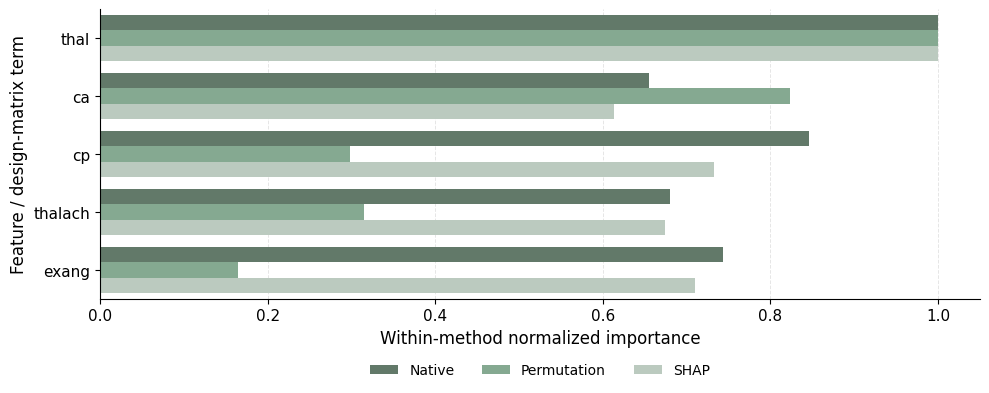

Saved: C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\images\results\stroke_global_importance.pdf


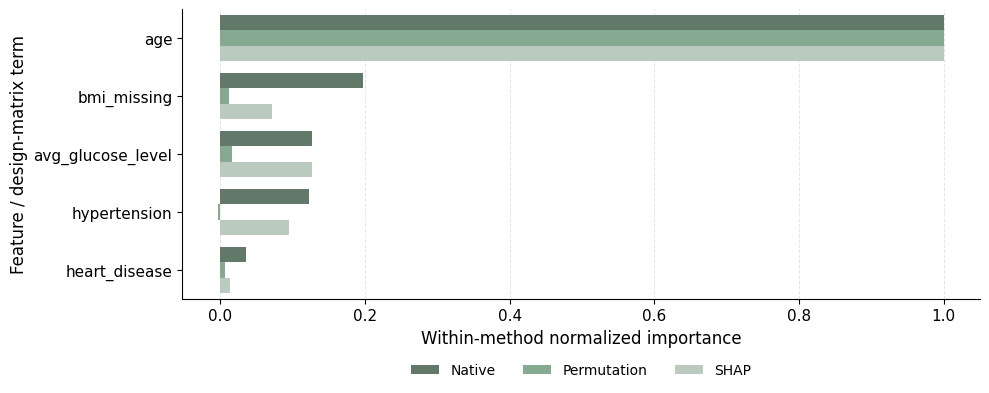

Saved: C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\images\results\diabetes_global_importance.pdf


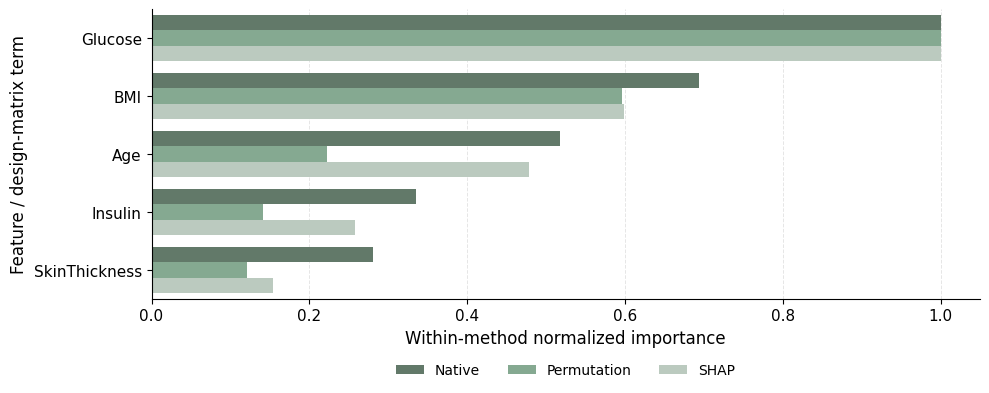

Saved: C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\images\results\ckd_global_importance.pdf


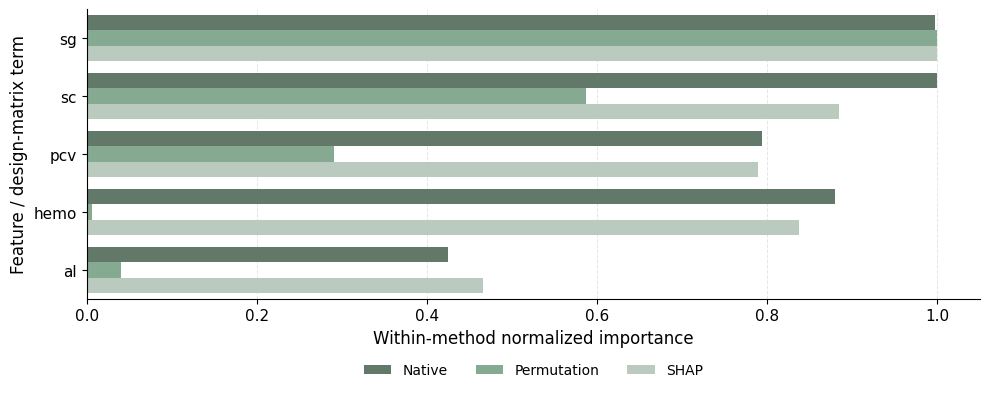

Saved: C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\images\results\hba1c_global_importance.pdf


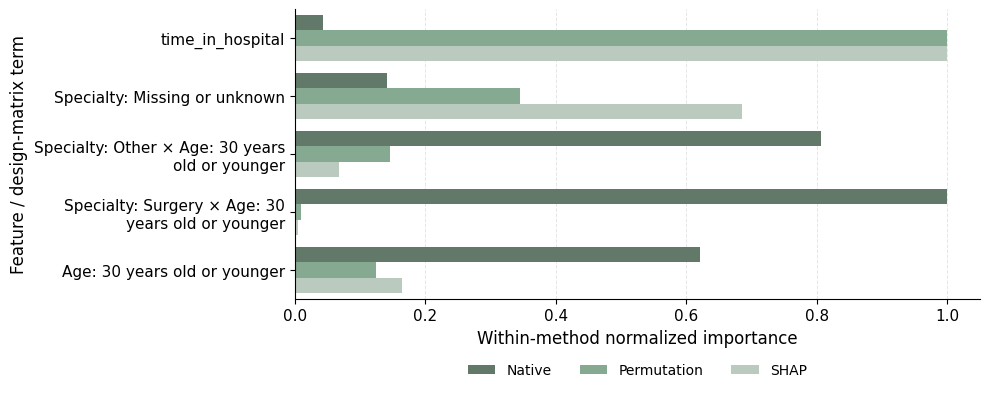

In [12]:
for dataset in DATASETS:

    plot_global_importance_combined(
        dataset,
        top_n=5
    )


### 1.2.2 Export global XAI tables


In [13]:
global_top5_df.to_csv(
    ANALYSIS_OUT / "global_top5_features.csv",
    index=False
)
global_overlap_df.to_csv(
    ANALYSIS_OUT / "global_top5_overlap.csv",
    index=False
)
common_global_features_df.to_csv(
    ANALYSIS_OUT / "global_common_top5_features.csv",
    index=False
)
global_rank_all_df.to_csv(
    ANALYSIS_OUT / "global_rank_comparison_all_features.csv",
    index=False
)


# 1.3 Agreement between XAI methods

Agreement is recalculated from the same intercept-filtered feature set used in section 1.2. The number of compared features is retained because correlation estimates across differently sized feature spaces are not directly equivalent.


,Dataset,Comparison,SpearmanRho,NFeaturesCompared
0,Heart,Native vs SHAP,0.978,13
1,Heart,Native vs Permutation,0.621,13
2,Heart,SHAP vs Permutation,0.615,13
3,Stroke,Native vs SHAP,0.893,7
4,Stroke,Native vs Permutation,0.739,7
5,Stroke,SHAP vs Permutation,0.631,7
6,Diabetes,Native vs SHAP,1.000,5
7,Diabetes,Native vs Permutation,1.000,5
8,Diabetes,SHAP vs Permutation,1.000,5
9,CKD,Native vs SHAP,0.981,24


Saved: C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\images\results\rank_agreement_all_datasets.pdf


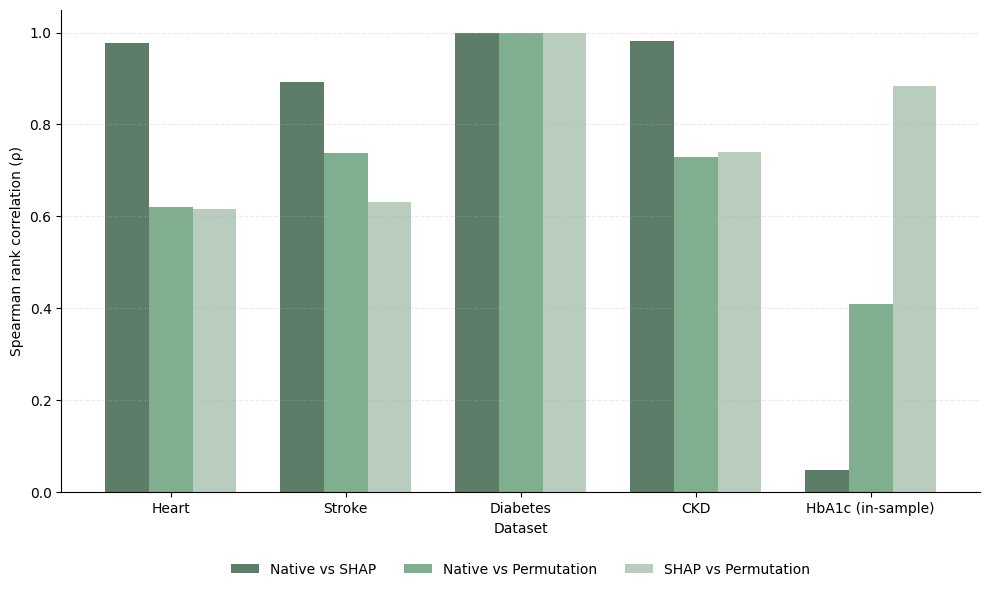

In [14]:
agreement_rows = []

for dataset in DATASETS:

    ranks = global_rank_table(dataset)

    comparisons = {
        "Native vs SHAP": (
            "NativeRank",
            "SHAPRank"
        ),
        "Native vs Permutation": (
            "NativeRank",
            "PermutationRank"
        ),
        "SHAP vs Permutation": (
            "SHAPRank",
            "PermutationRank"
        )
    }

    for comparison, (left, right) in comparisons.items():

        agreement_rows.append({
            "Dataset": DISPLAY_NAMES[dataset],
            "Comparison": comparison,
            "SpearmanRho": ranks[left].corr(
                ranks[right],
                method="spearman"
            ),
            "NFeaturesCompared": len(ranks)
        })


agreement_df = pd.DataFrame(
    agreement_rows
)

display(
    agreement_df.round(3)
)


comparison_order = [
    "Native vs SHAP",
    "Native vs Permutation",
    "SHAP vs Permutation"
]

dataset_order = [
    "Heart",
    "Stroke",
    "Diabetes",
    "CKD",
    "HbA1c (in-sample)"
]

pivot_df = (
    agreement_df
    .pivot(
        index="Dataset",
        columns="Comparison",
        values="SpearmanRho"
    )
    .reindex(
        index=dataset_order,
        columns=comparison_order
    )
)


colors = [
    "#5E7D68",
    "#7FAF8F",
    "#B8CDBE"
]


fig, ax = plt.subplots(
    figsize=(10, 6)
)

pivot_df.plot(
    kind="bar",
    ax=ax,
    color=colors,
    width=0.75
)

# Start at zero when all plotted values are non-negative.
# Preserve the negative range if future results require it.
lower = -1.05 if (pivot_df < 0).any().any() else 0
ax.set_ylim(lower, 1.05)

ax.set_ylabel(
    "Spearman rank correlation (ρ)"
)

ax.set_xlabel(
    "Dataset"
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.tick_params(
    axis="x",
    rotation=0
)

ax.legend(
    title="",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=3,
    frameon=False,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()

FIGURE_DIR = RESULTS_DIR.parent / "images" / "results"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

figure_path = (
    FIGURE_DIR
    / "rank_agreement_all_datasets.pdf"
)

fig.savefig(
    figure_path,
    bbox_inches="tight",
)

print("Saved:", figure_path)

plt.show()

agreement_df.to_csv(
    ANALYSIS_OUT
    / "rank_agreement_all_datasets.csv",
    index=False,
)


Saved: C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\images\results\rank_agreement_heatmap.pdf


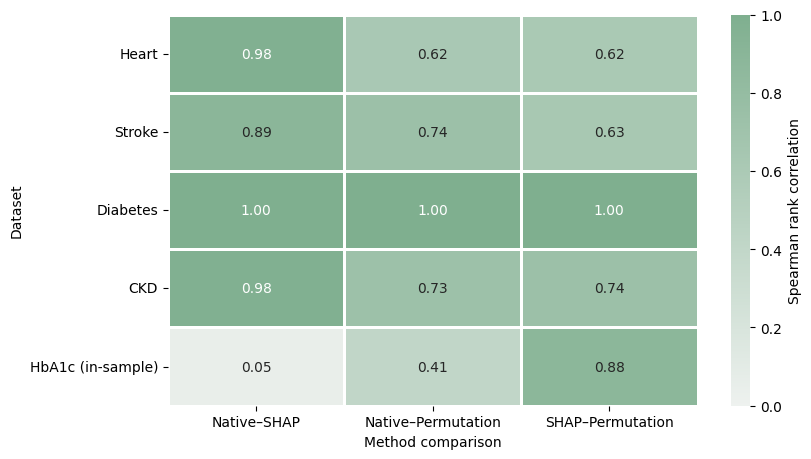

In [15]:
comparison_order = [
    "Native vs SHAP",
    "Native vs Permutation",
    "SHAP vs Permutation",
]

dataset_order = [
    "Heart",
    "Stroke",
    "Diabetes",
    "CKD",
    "HbA1c (in-sample)",
]

agreement_heatmap = (
    agreement_df
    .pivot(
        index="Dataset",
        columns="Comparison",
        values="SpearmanRho",
    )
    .reindex(
        index=dataset_order,
        columns=comparison_order,
    )
)

agreement_heatmap = agreement_heatmap.rename(
    columns={
        "Native vs SHAP": "Native–SHAP",
        "Native vs Permutation": "Native–Permutation",
        "SHAP vs Permutation": "SHAP–Permutation",
    }
)

fig, ax = plt.subplots(figsize=(8.5, 4.7))

sns.heatmap(
    agreement_heatmap,
    annot=True,
    fmt=".2f",
    cmap=sns.light_palette(
        "#7FAF8F",
        as_cmap=True,
    ),
    vmin=0,
    vmax=1,
    linewidths=1,
    linecolor="white",
    cbar_kws={
        "label": "Spearman rank correlation",
    },
    ax=ax,
)

ax.set_xlabel("Method comparison")
ax.set_ylabel("Dataset")
ax.tick_params(axis="y", rotation=0)

fig.tight_layout()

figure_path = (
    FIGURE_DIR
    / "rank_agreement_heatmap.pdf"
)

fig.savefig(
    figure_path,
    bbox_inches="tight",
)

print("Saved:", figure_path)

plt.show()


# 1.4 Stability of explanations

These outputs describe repeated-run permutation-importance stability. Missing stability is reported as unavailable rather than zero. Coefficients of variation should not be interpreted when mean importance is zero or near zero.


,Dataset,MeanStabilityRho,MeanTopKOverlap,NRankComparisons
0,Heart,0.700,0.645,4950
1,Stroke,0.812,0.741,4950
2,Diabetes,0.849,0.890,4950
3,CKD,0.949,0.759,4950
4,HbA1c (in-sample),NaN,NaN,0


Saved: C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\images\results\stability_ranks.pdf


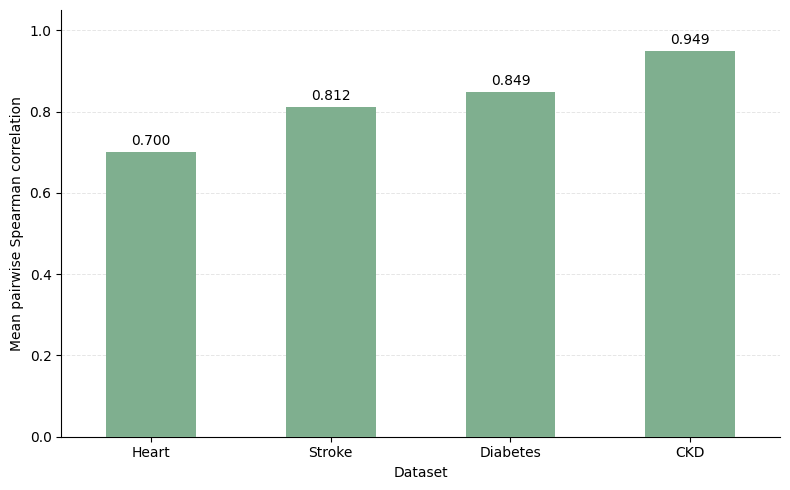

Saved: C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\images\results\stability_top3.pdf


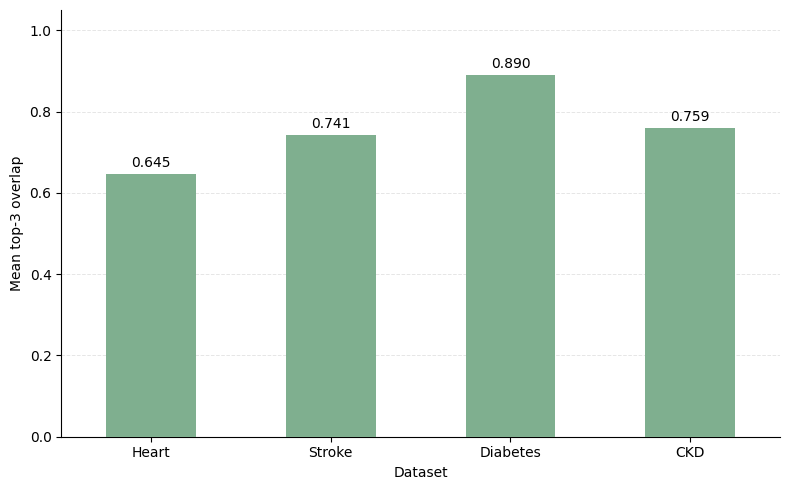

In [16]:
stability_summary_rows = []
feature_stability_frames = []

for dataset in DATASETS:
    rank_df = load_stability_rank(dataset)

    if rank_df is not None and not rank_df.empty:
        stability_summary_rows.append({
            "Dataset": DISPLAY_NAMES[dataset],
            "MeanStabilityRho": (
                rank_df["SpearmanRankCorrelation"].mean()
                if "SpearmanRankCorrelation" in rank_df.columns
                else np.nan
            ),
            "MeanTopKOverlap": (
                rank_df["TopKOverlap"].mean()
                if "TopKOverlap" in rank_df.columns
                else np.nan
            ),
            "NRankComparisons": len(rank_df)
        })
    else:
        stability_summary_rows.append({
            "Dataset": DISPLAY_NAMES[dataset],
            "MeanStabilityRho": np.nan,
            "MeanTopKOverlap": np.nan,
            "NRankComparisons": 0
        })

    feature_df = load_feature_stability(dataset)

    if feature_df is None or feature_df.empty:
        continue

    feature_df = feature_df.copy()
    feature_df.insert(0, "Dataset", DISPLAY_NAMES[dataset])
    feature_df["ImportanceCV"] = np.where(
        feature_df["MeanImportance"].abs() > 1e-12,
        feature_df["StdImportance"]
        / feature_df["MeanImportance"].abs(),
        np.nan
    )
    feature_stability_frames.append(feature_df)

stability_summary_df = pd.DataFrame(stability_summary_rows)

dataset_order = [
    "Heart",
    "Stroke",
    "Diabetes",
    "CKD",
    "HbA1c (in-sample)"
]

stability_summary_df["Dataset"] = pd.Categorical(
    stability_summary_df["Dataset"],
    categories=dataset_order,
    ordered=True
)

stability_summary_df = (
    stability_summary_df
    .sort_values("Dataset")
    .reset_index(drop=True)
)

feature_stability_df = pd.concat(
    feature_stability_frames,
    ignore_index=True
) if feature_stability_frames else pd.DataFrame()

display(stability_summary_df.round(3))

plots = [
    {
        "metric": "MeanStabilityRho",
        "ylabel": "Mean pairwise Spearman correlation",
        "filename": "stability_ranks.pdf",
    },
    {
        "metric": "MeanTopKOverlap",
        "ylabel": "Mean top-3 overlap",
        "filename": "stability_top3.pdf",
    },
]

FIGURE_DIR = RESULTS_DIR.parent / "images" / "results"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

for plot in plots:
    plot_data = stability_summary_df.dropna(
        subset=[plot["metric"]]
    )

    ax = plot_data.plot.bar(
        x="Dataset",
        y=plot["metric"],
        legend=False,
        figsize=(8, 5),
        color="#7FAF8F",
        zorder=3,
    )

    fig = ax.figure

    lower = (
        -1.05
        if (
            plot["metric"] == "MeanStabilityRho"
            and (plot_data[plot["metric"]] < 0).any()
        )
        else 0
    )

    ax.set_ylim(lower, 1.05)
    ax.set_xlabel("Dataset")
    ax.set_ylabel(plot["ylabel"])

    ax.bar_label(
        ax.containers[0],
        labels=[
            f"{value:.3f}"
            for value in plot_data[plot["metric"]]
        ],
        padding=3,
    )

    ax.set_axisbelow(True)
    ax.grid(
        axis="y",
        color="#E6E6E6",
        linestyle="--",
        linewidth=0.7,
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(
        axis="x",
        rotation=0,
    )

    fig.tight_layout()

    figure_path = FIGURE_DIR / plot["filename"]

    fig.savefig(
        figure_path,
        bbox_inches="tight",
    )

    print("Saved:", figure_path)
    plt.show()
stability_summary_df.to_csv(
    ANALYSIS_OUT / "stability_comparison.csv",
    index=False
)
feature_stability_df.to_csv(
    ANALYSIS_OUT / "feature_level_stability.csv",
    index=False
)


Saved: C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\images\results\stability_combined.pdf


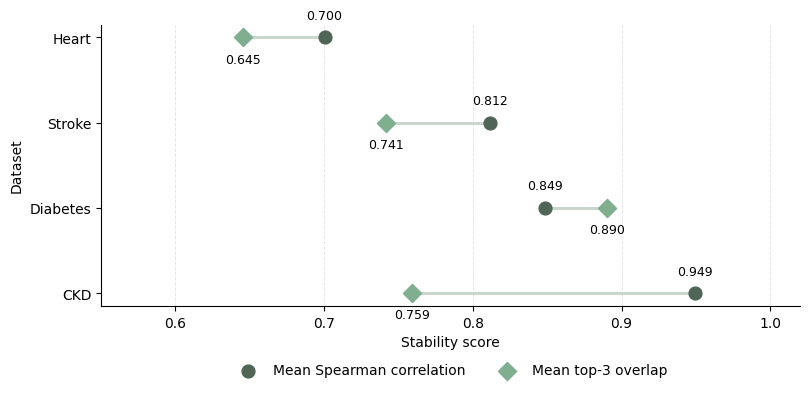

In [17]:

stability_plot_df = (
    stability_summary_df
    .dropna(
        subset=[
            "MeanStabilityRho",
            "MeanTopKOverlap",
        ]
    )
    .copy()
)

stability_dataset_order = [
    "Heart",
    "Stroke",
    "Diabetes",
    "CKD",
]

stability_plot_df["Dataset"] = pd.Categorical(
    stability_plot_df["Dataset"],
    categories=stability_dataset_order,
    ordered=True,
)

stability_plot_df = (
    stability_plot_df
    .sort_values("Dataset")
    .reset_index(drop=True)
)

y_positions = np.arange(
    len(stability_plot_df)
)

fig, ax = plt.subplots(figsize=(8.2, 4.4))

for y_position, rho, overlap in zip(
    y_positions,
    stability_plot_df["MeanStabilityRho"],
    stability_plot_df["MeanTopKOverlap"],
):
    ax.plot(
        [rho, overlap],
        [y_position, y_position],
        color="#C9D5CD",
        linewidth=2.2,
        zorder=1,
    )

ax.scatter(
    stability_plot_df["MeanStabilityRho"],
    y_positions,
    s=85,
    color="#4F6656",
    label="Mean Spearman correlation",
    zorder=3,
)

ax.scatter(
    stability_plot_df["MeanTopKOverlap"],
    y_positions,
    s=85,
    color="#7FAF8F",
    marker="D",
    label="Mean top-3 overlap",
    zorder=3,
)

for y_position, rho, overlap in zip(
    y_positions,
    stability_plot_df["MeanStabilityRho"],
    stability_plot_df["MeanTopKOverlap"],
):
    ax.text(
        rho,
        y_position - 0.18,
        f"{rho:.3f}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

    ax.text(
        overlap,
        y_position + 0.18,
        f"{overlap:.3f}",
        ha="center",
        va="top",
        fontsize=9,
    )

ax.set_yticks(
    y_positions,
    stability_plot_df["Dataset"].astype(str),
)

ax.invert_yaxis()
ax.set_xlim(0.55, 1.02)

ax.set_xlabel("Stability score")
ax.set_ylabel("Dataset")

ax.set_axisbelow(True)
ax.grid(
    axis="x",
    color="#E6E6E6",
    linestyle="--",
    linewidth=0.7,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.16),
    ncol=2,
    frameon=False,
)

fig.tight_layout(
    rect=[0, 0.06, 1, 1]
)

figure_path = (
    FIGURE_DIR
    / "stability_combined.pdf"
)

fig.savefig(
    figure_path,
    bbox_inches="tight",
)

print("Saved:", figure_path)

plt.show()


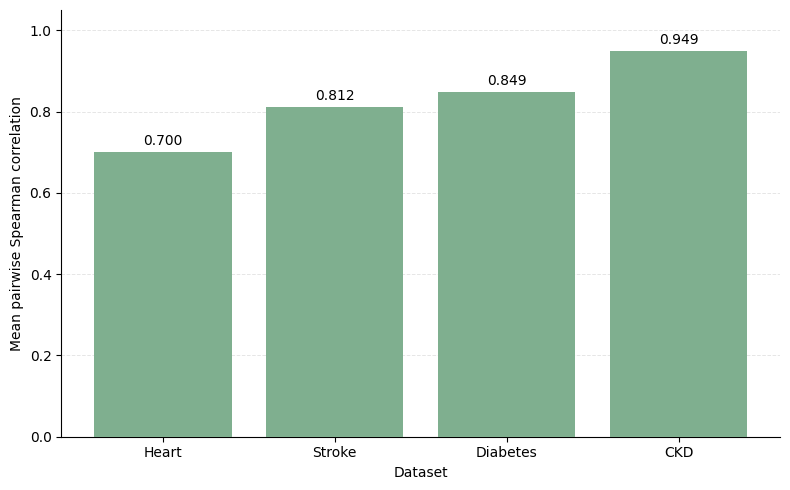

Saved: C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\images\results\stability_ranks.pdf


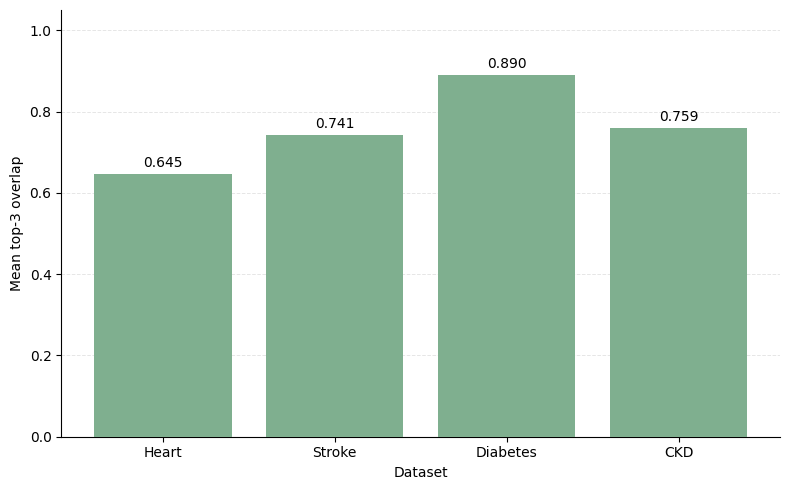

Saved: C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\images\results\stability_top3.pdf


In [18]:

FIGURE_DIR = RESULTS_DIR.parent / "images" / "results"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

plots = [
    {
        "metric": "MeanStabilityRho",
        "ylabel": "Mean pairwise Spearman correlation",
        "filename": "stability_ranks.pdf",
    },
    {
        "metric": "MeanTopKOverlap",
        "ylabel": "Mean top-3 overlap",
        "filename": "stability_top3.pdf",
    },
]

for plot in plots:
    plot_data = stability_summary_df.dropna(
        subset=[plot["metric"]]
    )

    fig, ax = plt.subplots(figsize=(8, 5))

    bars = ax.bar(
        plot_data["Dataset"].astype(str),
        plot_data[plot["metric"]],
        color="#7FAF8F",
        zorder=3,
    )

    ax.bar_label(
        bars,
        labels=[
            f"{value:.3f}"
            for value in plot_data[plot["metric"]]
        ],
        padding=3,
    )

    ax.set_ylim(0, 1.05)
    ax.set_xlabel("Dataset")
    ax.set_ylabel(plot["ylabel"])

    ax.set_axisbelow(True)
    ax.grid(
        axis="y",
        color="#E6E6E6",
        linestyle="--",
        linewidth=0.7,
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    fig.tight_layout()

    output_path = FIGURE_DIR / plot["filename"]

    fig.savefig(
        output_path,
        bbox_inches="tight",
    )

    plt.show()
    print("Saved:", output_path)


# 1.5 Local explanations and representative cases


### 1.5.1 Representative-case availability and identifier validation


In [19]:
local_case_rows = []
case_map_rows = []

for dataset in DATASETS:
    path = RESULTS_DIR / dataset / "representative_cases.csv"

    if not path.exists():
        continue

    cases = pd.read_csv(path)
    required = {"CaseType", "CaseIndex", "y_true", "y_pred", "y_prob"}
    missing = required.difference(cases.columns)

    if missing:
        raise ValueError(
            f"{dataset} representative cases are missing: "
            f"{sorted(missing)}"
        )

    for _, row in cases.iterrows():
        local_case_rows.append({
            "Dataset": DISPLAY_NAMES[dataset],
            "CaseIndex": row["CaseIndex"],
            "CaseType": row["CaseType"],
            "True": row["y_true"],
            "Predicted": row["y_pred"],
            "Probability": row["y_prob"],
            "CaseRank": row.get("CaseRank", 1)
        })
        case_map_rows.append({
            "Dataset": DISPLAY_NAMES[dataset],
            "CaseIndex": row["CaseIndex"],
            "CaseType": row["CaseType"],
            "CaseRank": row.get("CaseRank", 1)
        })

local_cases_df = pd.DataFrame(local_case_rows)
case_map_df = pd.DataFrame(case_map_rows)

if case_map_df.duplicated(["Dataset", "CaseIndex"]).any():
    raise ValueError("Representative-case identifiers are not unique")

case_availability = (
    local_cases_df
    .assign(Available=1)
    .pivot_table(
        index="Dataset",
        columns="CaseType",
        values="Available",
        aggfunc="max",
        fill_value=0
    )
    .reset_index()
)

display(local_cases_df.round(4))
display(case_availability)


,Dataset,CaseIndex,CaseType,True,Predicted,Probability,CaseRank
0,Heart,84,TP,1.0,1,0.7621,1
1,Heart,2,TP,1.0,1,0.7561,2
2,Heart,125,TP,1.0,1,0.7455,3
3,Heart,14,TP,1.0,1,0.7368,4
4,Heart,46,TP,1.0,1,0.7357,5
...,...,...,...,...,...,...,...
207,HbA1c (in-sample),48516,Borderline,0.0,0,0.2926,6
208,HbA1c (in-sample),24014,Borderline,0.0,0,0.2861,7
209,HbA1c (in-sample),37173,Borderline,0.0,0,0.2684,8
210,HbA1c (in-sample),39776,Borderline,0.0,0,0.2625,9


CaseType,Dataset,Borderline,FN,FP,TN,TP
0,CKD,1,1,1,1,1
1,Diabetes,1,1,1,1,1
2,HbA1c (in-sample),1,1,0,1,0
3,Heart,1,1,1,1,1
4,Stroke,1,1,1,1,1


### 1.5.2 Strongest LIME rules per representative case

LIME weight direction is interpreted relative to the positive class. Cross-dataset weight magnitudes should not be treated as being on a common scale.


In [20]:
raw_lime_frames = []
category_lime_frames = []
seed_stability_frames = []

for dataset in DATASETS:
    raw_path = RESULTS_DIR / dataset / "lime_explanations.csv"
    summary_path = RESULTS_DIR / dataset / "lime_summary.csv"
    seed_path = RESULTS_DIR / dataset / "lime_seed_stability.csv"

    if not raw_path.exists():
        continue

    raw = pd.read_csv(raw_path)
    required = {
        "CaseIndex", "CaseType", "CaseRank", "LIMESeed",
        "Probability", "Rule", "Weight"
    }
    missing = required.difference(raw.columns)
    if missing:
        raise ValueError(
            f"{dataset} repeated LIME table is missing: {sorted(missing)}"
        )

    seed_counts = raw.groupby(["CaseType", "CaseIndex"])["LIMESeed"].nunique()
    if not (seed_counts == 20).all():
        raise ValueError(f"{dataset} does not contain 20 LIME seeds for every case")

    raw["Dataset"] = DISPLAY_NAMES[dataset]
    raw_lime_frames.append(raw)

    if summary_path.exists():
        category_summary = pd.read_csv(summary_path)
        category_summary.insert(0, "Dataset", DISPLAY_NAMES[dataset])
        category_lime_frames.append(category_summary)

    if seed_path.exists():
        seed_summary = pd.read_csv(seed_path)
        seed_summary.insert(0, "Dataset", DISPLAY_NAMES[dataset])
        seed_stability_frames.append(seed_summary)

raw_lime_df = pd.concat(raw_lime_frames, ignore_index=True)
lime_repeated_summary_df = pd.concat(category_lime_frames, ignore_index=True)
lime_seed_stability_df = pd.concat(seed_stability_frames, ignore_index=True)

# Average each rule over the 20 perturbation seeds for each observation.
case_rule_summary = (
    raw_lime_df
    .groupby(
        ["Dataset", "CaseIndex", "CaseType", "CaseRank", "Rule"],
        as_index=False,
    )
    .agg(
        Weight=("Weight", "mean"),
        WeightStd=("Weight", "std"),
        MeanAbsWeight=("Weight", lambda values: values.abs().mean()),
        NSeeds=("LIMESeed", "nunique"),
        Probability=("Probability", "first"),
    )
)

case_rule_summary["Rank"] = (
    case_rule_summary
    .groupby(["Dataset", "CaseIndex"])["MeanAbsWeight"]
    .rank(method="first", ascending=False)
    .astype(int)
)

lime_summary_df = case_rule_summary.loc[
    case_rule_summary["Rank"] <= 5
].copy()

lime_with_cases_df = lime_summary_df.merge(
    local_cases_df[
        ["Dataset", "CaseIndex", "CaseType", "CaseRank", "True", "Predicted"]
    ],
    on=["Dataset", "CaseIndex", "CaseType", "CaseRank"],
    how="left",
    validate="many_to_one",
)

if lime_with_cases_df[["True", "Predicted"]].isna().any().any():
    raise ValueError("Some repeated LIME explanations could not be mapped to cases")

lime_with_cases_df["Direction"] = np.select(
    [lime_with_cases_df["Weight"] > 0, lime_with_cases_df["Weight"] < 0],
    ["Supports positive class", "Supports negative class"],
    default="Neutral",
)
lime_with_cases_df["OutcomeGroup"] = lime_with_cases_df["CaseType"].replace({
    "TP": "Correct", "TN": "Correct", "FP": "Error",
    "FN": "Error", "Borderline": "Borderline",
})

display(
    raw_lime_df.groupby(["Dataset", "CaseType"])
    .agg(NCases=("CaseIndex", "nunique"), NSeeds=("LIMESeed", "nunique"))
)
display(lime_repeated_summary_df.head(30).round(4))
display(
    lime_seed_stability_df.groupby("Dataset")[[
        "MeanPairwiseSpearman", "MeanTopKOverlap",
        "MeanRuleWeightSD", "MeanRuleSignConsistency"
    ]].mean().round(4)
)


NCases  NSeeds
Dataset           CaseType                  
CKD               Borderline      10      20
                  FN               1      20
                  FP               1      20
                  TN              10      20
                  TP              10      20
Diabetes          Borderline      10      20
                  FN              10      20
                  FP              10      20
                  TN              10      20
                  TP              10      20
HbA1c (in-sample) Borderline      10      20
                  FN              10      20
                  TN              10      20
Heart             Borderline      10      20
                  FN              10      20
                  FP              10      20
                  TN              10      20
                  TP              10      20
Stroke            Borderline      10      20
                  FN              10      20
                  FP              10      20
                  TN              10      20
                  TP              10      20

,Dataset,CaseType,Rule,MeanWeight,StdWeight,MeanAbsWeight,MedianWeight,PositiveWeightFraction,NExplanations,NCases,NSeeds,SelectionFrequency
0,Heart,Borderline,cp <= -0.21,-0.0605,0.0012,0.0605,-0.0605,0.0,120,6,20,0.600
1,Heart,Borderline,0.32 < cp <= 0.85,0.0604,0.0011,0.0604,0.0603,1.0,80,4,20,0.400
2,Heart,Borderline,thalach <= -0.52,0.0486,0.0011,0.0486,0.0485,1.0,40,2,20,0.200
3,Heart,Borderline,ca > 0.40,0.0403,0.0014,0.0403,0.0404,1.0,20,1,20,0.100
4,Heart,Borderline,-0.70 < exang <= 1.42,0.0396,0.0013,0.0396,0.0396,1.0,40,2,20,0.200
5,Heart,Borderline,exang <= -0.70,-0.0393,0.0013,0.0393,-0.0392,0.0,160,8,20,0.800
6,Heart,Borderline,oldpeak > 0.48,0.0366,0.0008,0.0366,0.0366,1.0,20,1,20,0.100
7,Heart,Borderline,-0.94 < thal <= 1.11,0.0355,0.0011,0.0355,0.0355,1.0,80,4,20,0.400
8,Heart,Borderline,thal <= -0.94,-0.0353,0.0012,0.0353,-0.0353,0.0,120,6,20,0.600
9,Heart,Borderline,ca <= -0.73,-0.0243,0.0012,0.0243,-0.0243,0.0,140,7,20,0.700


,MeanPairwiseSpearman,MeanTopKOverlap,MeanRuleWeightSD,MeanRuleSignConsistency
Dataset,,,,
CKD,0.8981,0.9191,0.0071,0.8713
Diabetes,0.9558,0.9259,0.0066,0.9998
HbA1c (in-sample),0.9445,0.8922,0.0269,0.7995
Heart,0.9626,0.9537,0.0030,0.9000
Stroke,0.9687,0.9981,0.0091,0.8153


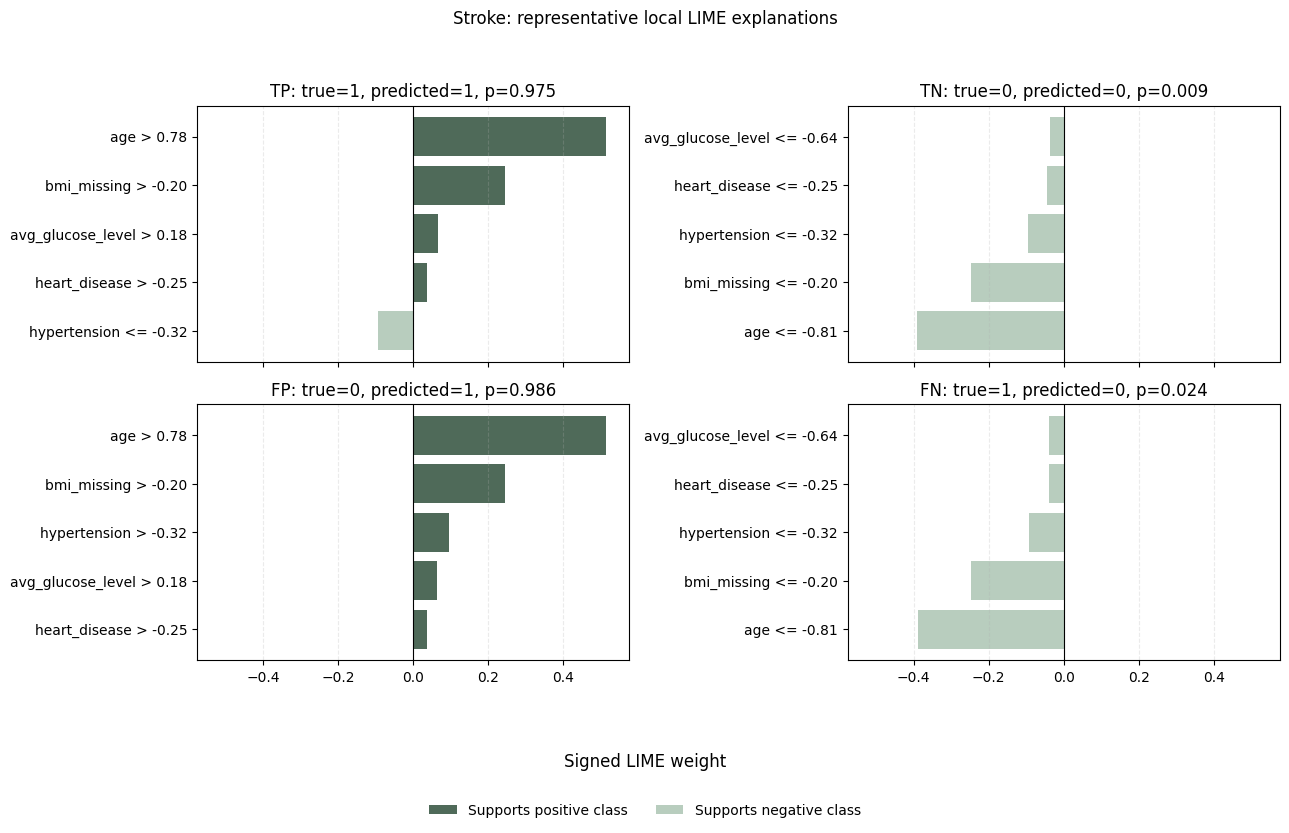

In [21]:

stroke_case_order = ["TP", "TN", "FP", "FN"]

stroke_lime = lime_with_cases_df[
    (lime_with_cases_df["Dataset"] == "Stroke")
    & (lime_with_cases_df["CaseType"].isin(stroke_case_order))
    & (lime_with_cases_df["Rank"] <= 5)
    & (lime_with_cases_df["CaseRank"] == 1)
].copy()

stroke_case_metadata = local_cases_df[
    (local_cases_df["Dataset"] == "Stroke")
    & (local_cases_df["CaseType"].isin(stroke_case_order))
    & (local_cases_df["CaseRank"] == 1)
].copy()

if stroke_lime.empty:
    raise ValueError("No representative Stroke LIME results were found.")

max_abs_weight = stroke_lime["Weight"].abs().max()
x_limit = max_abs_weight * 1.12

fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 8.5),
    sharex=True
)

axes = axes.ravel()

positive_color = "#4F6A59"
negative_color = "#B8CDBE"

for ax, case_type in zip(axes, stroke_case_order):
    case_rules = (
        stroke_lime[
            stroke_lime["CaseType"] == case_type
        ]
        .sort_values("Weight")
        .copy()
    )

    metadata = stroke_case_metadata[
        stroke_case_metadata["CaseType"] == case_type
    ].iloc[0]

    labels = [
        fill(str(rule), width=34)
        for rule in case_rules["Rule"]
    ]

    colors = [
        positive_color if weight > 0 else negative_color
        for weight in case_rules["Weight"]
    ]

    ax.barh(
        labels,
        case_rules["Weight"],
        color=colors
    )

    ax.axvline(
        0,
        color="black",
        linewidth=0.8
    )

    ax.set_xlim(
        -x_limit,
        x_limit
    )

    ax.grid(
        axis="x",
        linestyle="--",
        alpha=0.25
    )

    ax.set_title(
        f"{case_type}: true={int(metadata['True'])}, "
        f"predicted={int(metadata['Predicted'])}, "
        f"p={metadata['Probability']:.3f}"
    )

fig.suptitle(
    "Stroke: representative local LIME explanations",
    y=0.98
)

fig.supxlabel(
    "Signed LIME weight",
    y=0.085
)

fig.legend(
    handles=[
        Patch(
            facecolor=positive_color,
            label="Supports positive class"
        ),
        Patch(
            facecolor=negative_color,
            label="Supports negative class"
        )
    ],
    loc="lower center",
    bbox_to_anchor=(0.5, 0.015),
    ncol=2,
    frameon=False
)

plt.tight_layout(
    rect=[0, 0.13, 1, 0.95]
)

FIGURE_DIR = RESULTS_DIR.parent / "images" / "results"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

figure_path = (
    FIGURE_DIR
    / "stroke_representative_lime_v2.pdf"
)

fig.savefig(
    figure_path,
    bbox_inches="tight"
)

plt.show()


Saved: C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\images\results\representative_lime_heart.pdf


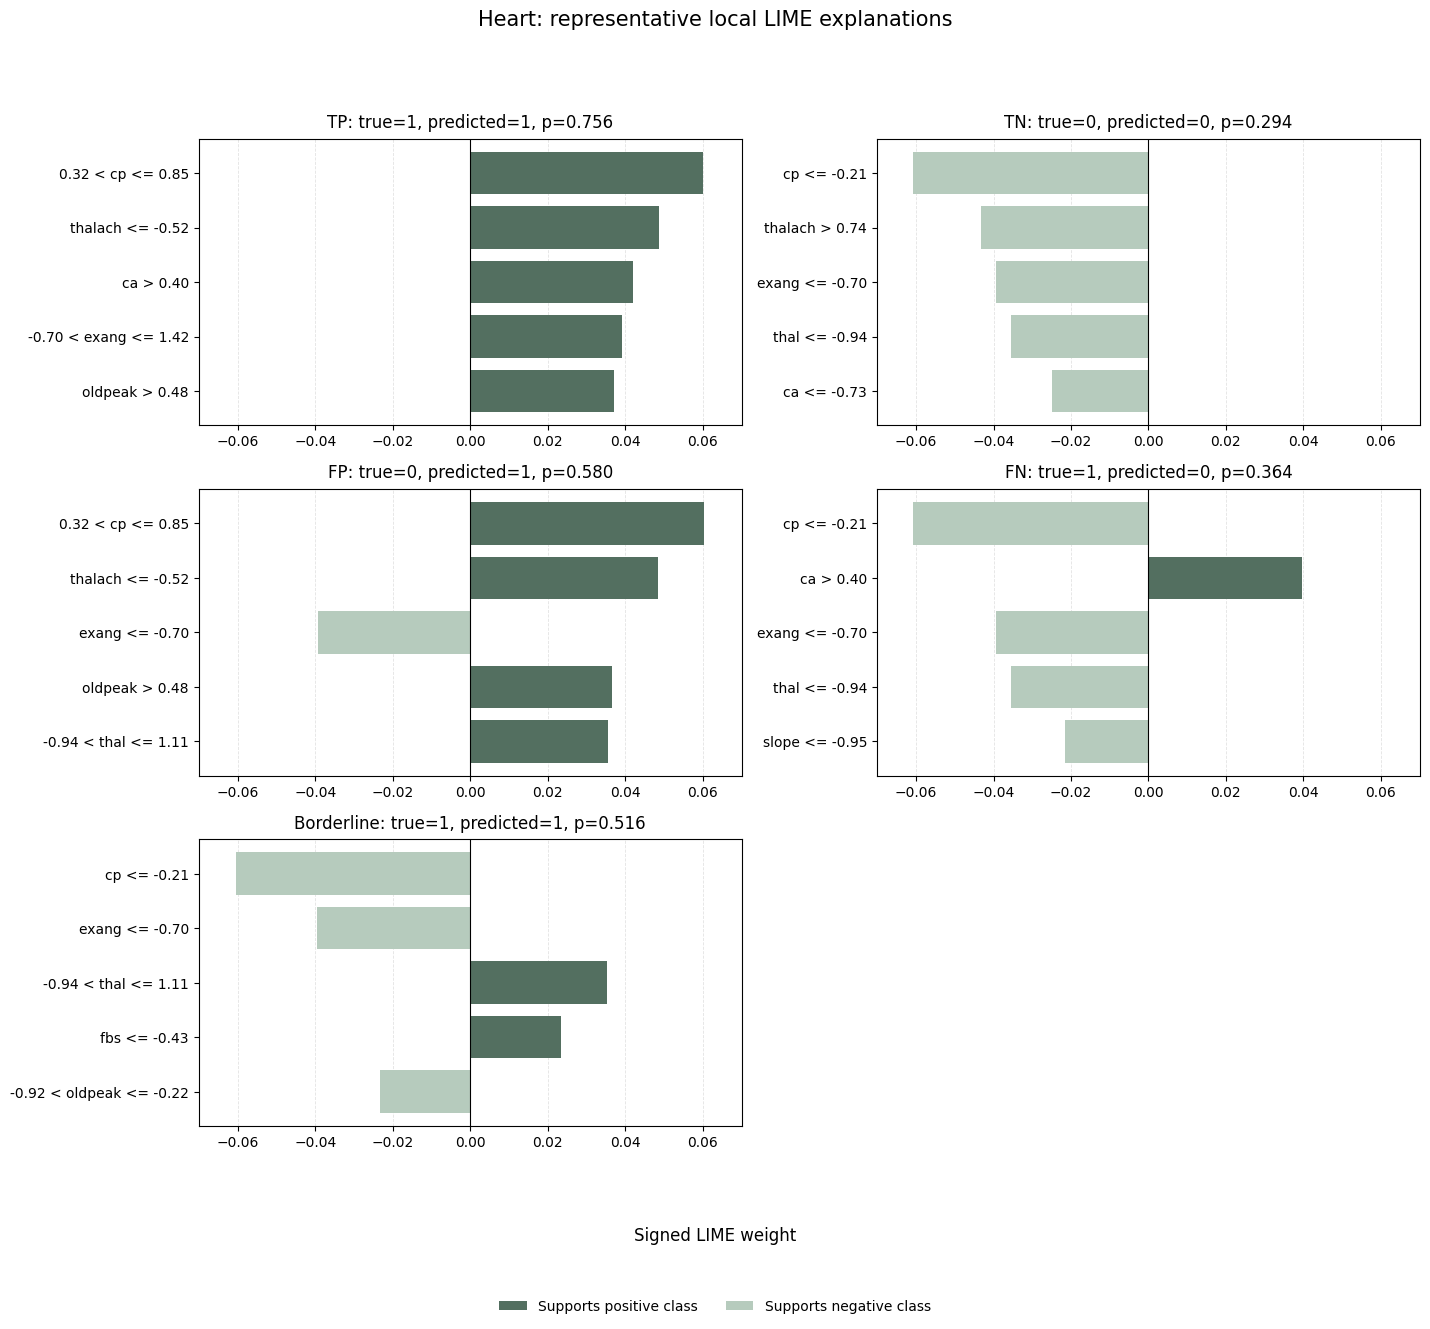

Saved: C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\images\results\representative_lime_stroke.pdf


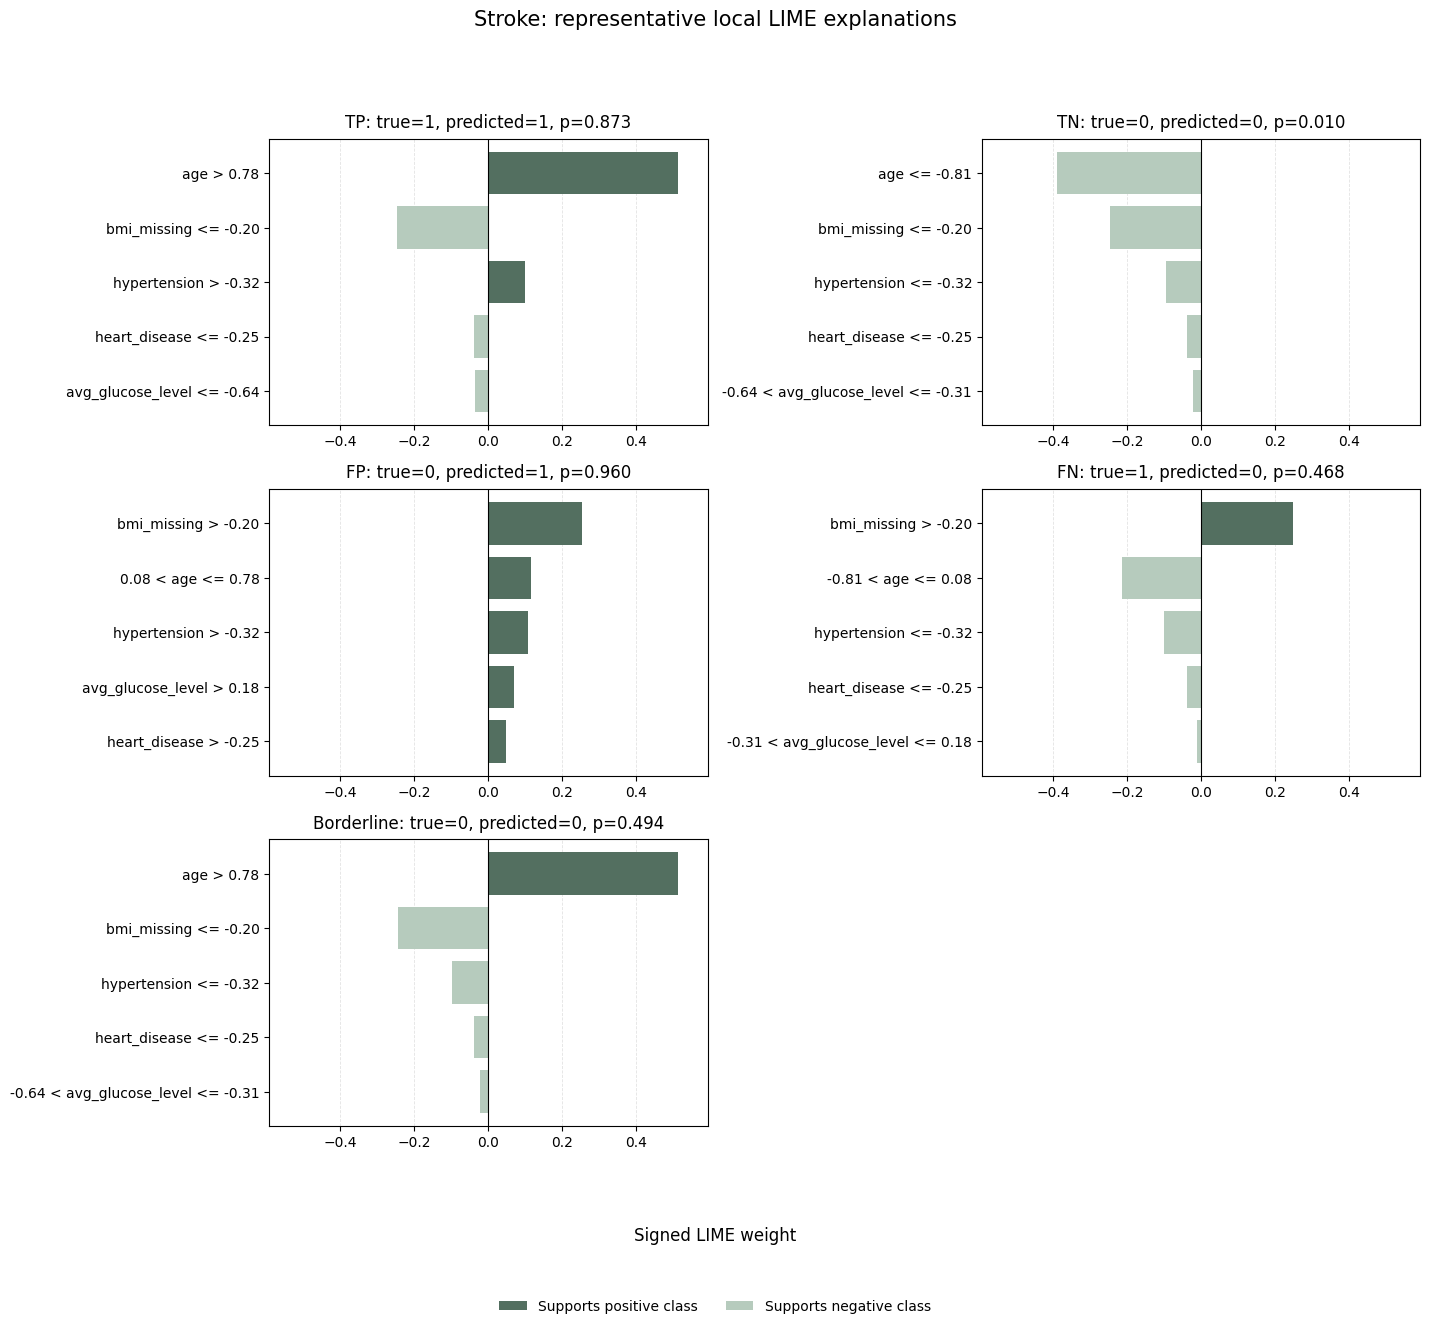

Saved: C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\images\results\representative_lime_diabetes.pdf


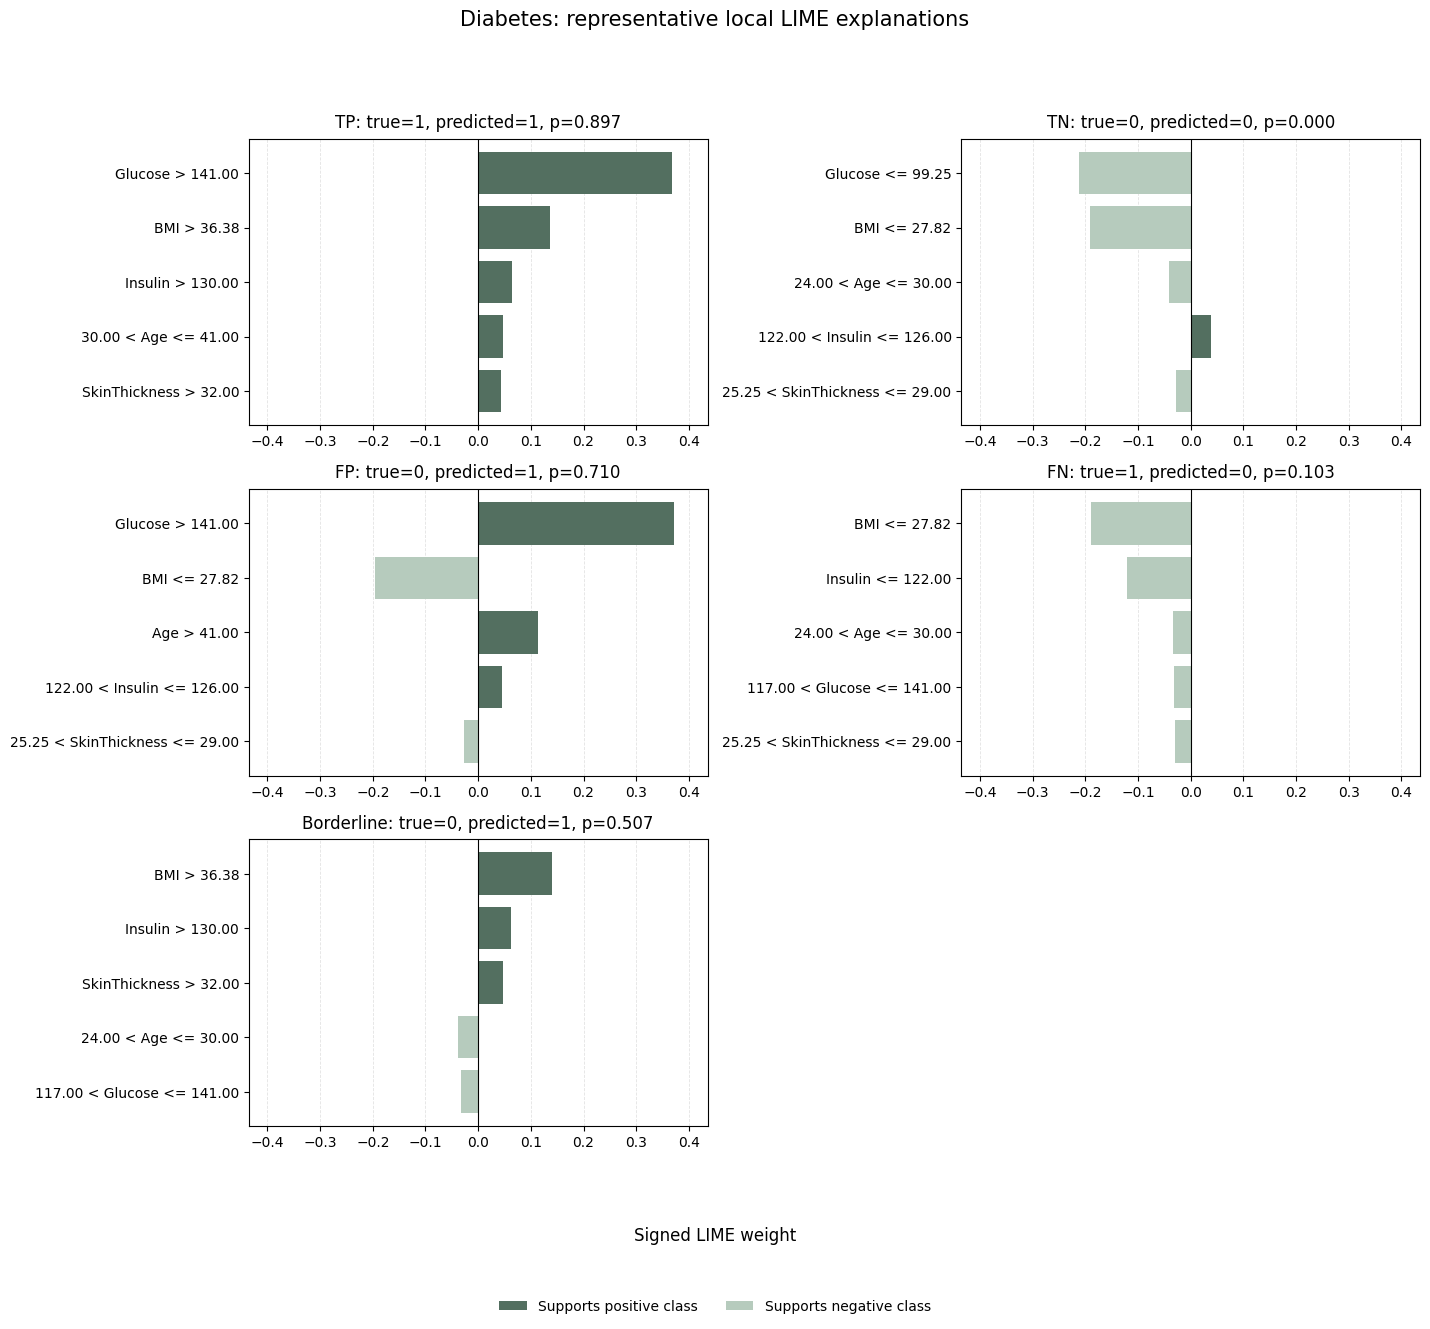

Saved: C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\images\results\representative_lime_ckd.pdf


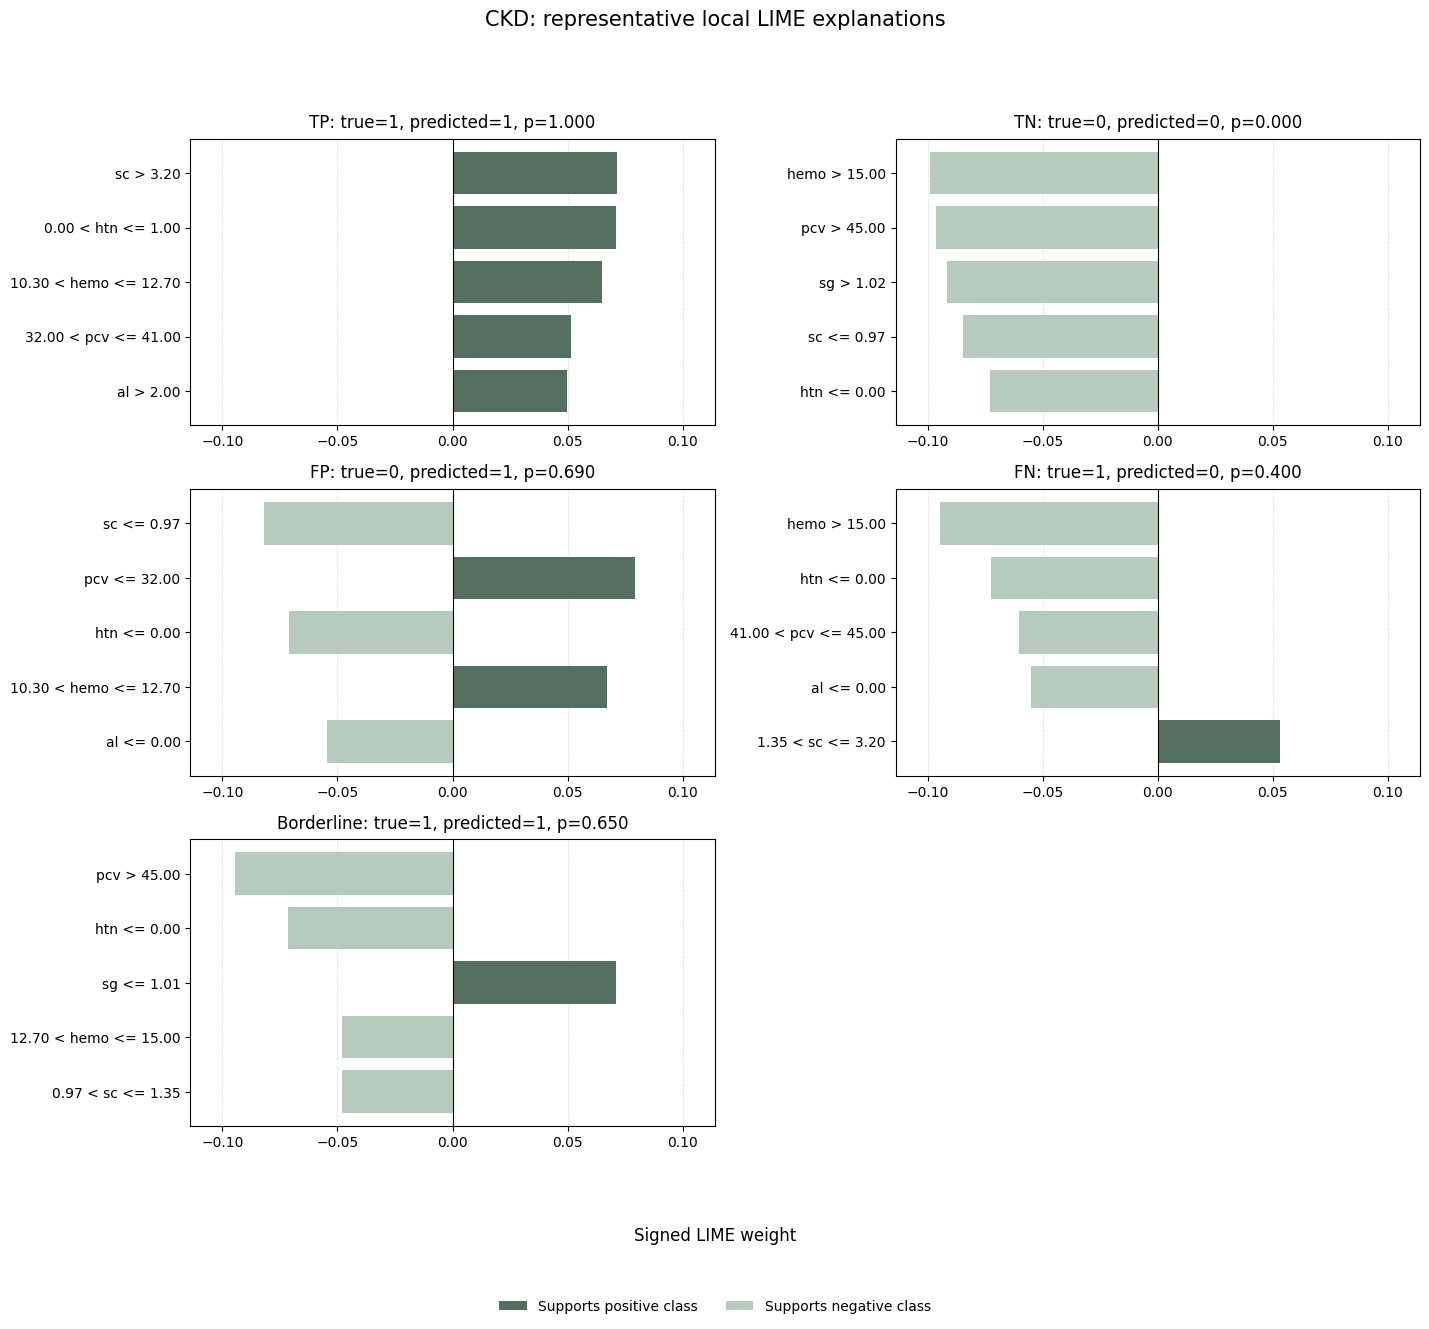

Saved: C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\images\results\representative_lime_hba1c.pdf


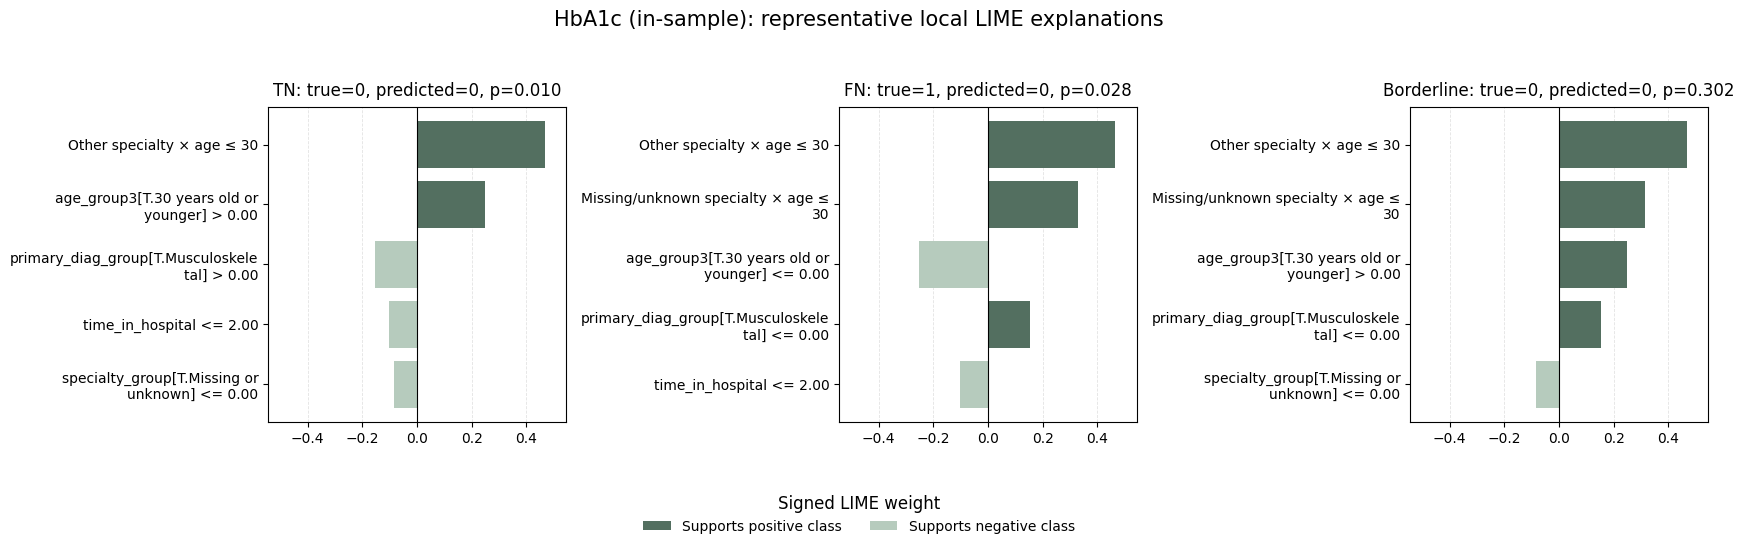

In [22]:



# Configure the figure.

case_order = ["TP", "TN", "FP", "FN", "Borderline"]

positive_colour = "#536f60"
negative_colour = "#b6cbbd"

figure_dir = Path("../../images/results").resolve()
figure_dir.mkdir(parents=True, exist_ok=True)


# Format LIME rules for presentation.

def readable_lime_rule(rule):
    """Convert an exported LIME rule to a readable label."""
    rule = str(rule)

    replacements = {
        "specialty_group[T.Other]:age_group3[T.30 years old or younger]":
            "Other specialty × age ≤ 30",

        "specialty_group[T.Family/general practice]:age_group3[T.30 years old or younger]":
            "Family/general practice × age ≤ 30",

        "specialty_group[T.Internal Medicine]:age_group3[T.30 years old or younger]":
            "Internal Medicine × age ≤ 30",

        "specialty_group[T.Missing or unknown]:age_group3[T.30 years old or younger]":
            "Missing/unknown specialty × age ≤ 30",

        "specialty_group[T.Surgery]:age_group3[T.30 years old or younger]":
            "Surgery × age ≤ 30",
    }

    for original, replacement in replacements.items():
        rule = rule.replace(original, replacement)

    # Remove the technical binary-variable ending from the
    # simplified HbA1c interaction labels.
    if "× age ≤ 30" in rule:
        rule = re.sub(
            r"\s*(?:<=|>)\s*0(?:\.0+)?$",
            "",
            rule
        )

    # Wrap long labels so that they fit inside the figure.
    return textwrap.fill(rule, width=33)


# Validate the required local-explanation data.

required_columns = {
    "Dataset",
    "CaseIndex",
    "CaseType",
    "Rule",
    "Weight",
}

missing_columns = required_columns.difference(
    lime_with_cases_df.columns
)

if missing_columns:
    raise ValueError(
        "lime_with_cases_df is missing these columns: "
        + ", ".join(sorted(missing_columns))
    )


# Use the dissertation dataset order.

preferred_dataset_order = [
    "Heart",
    "Stroke",
    "Diabetes",
    "CKD",
    "HbA1c",
    "HbA1c (in-sample)",
]

available_datasets = (
    lime_with_cases_df["Dataset"]
    .dropna()
    .astype(str)
    .unique()
    .tolist()
)

datasets = [
    dataset
    for dataset in preferred_dataset_order
    if dataset in available_datasets
]

# Add any unexpected dataset labels at the end.
datasets.extend(
    dataset
    for dataset in available_datasets
    if dataset not in datasets
)


# Create one representative LIME figure per dataset.

# Add True and Predicted values to the LIME plotting data.
lime_plot_df = lime_with_cases_df.copy()

if (
    "True" not in lime_plot_df.columns
    or "Predicted" not in lime_plot_df.columns
):

    merge_keys = [
        column
        for column in ["Dataset", "CaseIndex", "CaseType"]
        if column in lime_plot_df.columns
        and column in local_cases_df.columns
    ]

    metadata_columns = [
        column
        for column in ["True", "Predicted"]
        if column in local_cases_df.columns
    ]

    if not merge_keys:
        raise ValueError(
            "No common columns were found for matching "
            "lime_with_cases_df with local_cases_df."
        )

    if not metadata_columns:
        raise ValueError(
            "local_cases_df does not contain the True and "
            "Predicted columns."
        )

    metadata_to_merge = (
        local_cases_df[
            merge_keys + metadata_columns
        ]
        .drop_duplicates(subset=merge_keys)
    )

    lime_plot_df = lime_plot_df.merge(
        metadata_to_merge,
        on=merge_keys,
        how="left"
    )


for dataset_name in datasets:

    dataset_lime = lime_plot_df[
        lime_plot_df["Dataset"].astype(str) == dataset_name
    ].copy()

    if dataset_lime.empty:
        print(
            f"No representative cases found for {dataset_name}"
        )
        continue

    # Make HbA1c's Patsy interaction terms readable.
    if dataset_name.startswith("HbA1c"):
        dataset_lime["Rule"] = (
            dataset_lime["Rule"]
            .apply(readable_lime_rule)
        )

    # Determine which representative case types are available.
    available_case_types = (
        dataset_lime["CaseType"]
        .dropna()
        .astype(str)
        .unique()
        .tolist()
    )

    case_types = [
        case_type
        for case_type in case_order
        if case_type in available_case_types
    ]

    if not case_types:
        print(
            f"No representative cases found for {dataset_name}"
        )
        continue

    number_of_cases = len(case_types)
    # Select the dataset-specific figure layout.

    if dataset_name.startswith("HbA1c"):
        # HbA1c has TN, FN and Borderline: show them horizontally.
        nrows = 1
        ncols = number_of_cases
        figsize = (18, 5.5)

    elif number_of_cases == 4:
        # CKD has four representative cases.
        nrows = 2
        ncols = 2
        figsize = (15, 9)

    else:
        # Heart, Stroke and Diabetes have five cases.
        ncols = 2
        nrows = int(np.ceil(number_of_cases / ncols))
        figsize = (15, 4.5 * nrows)

    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=figsize,
        squeeze=False
    )

    axes_flat = axes.flatten()

    # Use the same x-axis range for all cases within this dataset.
    maximum_absolute_weight = (
        dataset_lime["Weight"]
        .astype(float)
        .abs()
        .max()
    )

    if pd.isna(maximum_absolute_weight) or maximum_absolute_weight == 0:
        maximum_absolute_weight = 1.0

    x_limit = maximum_absolute_weight * 1.15

    # Draw each available representative case.

    for axis_number, case_type in enumerate(case_types):

        ax = axes_flat[axis_number]

        case_rows = dataset_lime[
            dataset_lime["CaseType"].astype(str) == case_type
        ].copy()

        # If more than one case exists for this type, use the first
        # representative case index.
        representative_case_index = (
            case_rows["CaseIndex"]
            .dropna()
            .iloc[0]
        )

        case_rows = case_rows[
            case_rows["CaseIndex"] == representative_case_index
        ].copy()

        # Retain the five strongest local rules.
        case_rows["AbsoluteWeight"] = (
            case_rows["Weight"]
            .astype(float)
            .abs()
        )

        case_rows = (
            case_rows
            .sort_values(
                "AbsoluteWeight",
                ascending=False
            )
            .head(5)
            .sort_values(
                "AbsoluteWeight",
                ascending=True
            )
        )

        weights = case_rows["Weight"].astype(float)
        rules = case_rows["Rule"].astype(str)

        colours = [
            positive_colour if weight > 0 else negative_colour
            for weight in weights
        ]

        ax.barh(
            rules,
            weights,
            color=colours,
            edgecolor="none",
            height=0.78
        )

        ax.axvline(
            0,
            color="black",
            linewidth=0.8
        )

        ax.set_xlim(-x_limit, x_limit)

        ax.grid(
            axis="x",
            linestyle="--",
            linewidth=0.6,
            alpha=0.35
        )

        ax.set_axisbelow(True)

        # Retrieve the observed class, prediction, and probability.

        first_row = case_rows.iloc[0]

        true_value = (
            first_row["True"]
            if "True" in case_rows.columns
            else np.nan
        )

        predicted_value = (
            first_row["Predicted"]
            if "Predicted" in case_rows.columns
            else np.nan
        )

        probability = (
            first_row["Probability"]
            if "Probability" in case_rows.columns
            else np.nan
        )

        def format_class_value(value):
            """Format a class value for display."""
            if pd.isna(value):
                return "NA"

            try:
                return str(int(float(value)))
            except (TypeError, ValueError):
                return str(value)

        true_text = format_class_value(true_value)
        predicted_text = format_class_value(predicted_value)

        try:
            probability_text = f"{float(probability):.3f}"
        except (TypeError, ValueError):
            probability_text = "NA"

        ax.set_title(
            f"{case_type}: true={true_text}, "
            f"predicted={predicted_text}, "
            f"p={probability_text}",
            fontsize=12,
            pad=8
        )

        ax.tick_params(
            axis="both",
            labelsize=10
        )

        ax.set_xlabel("")
        ax.set_ylabel("")

    # Hide any unused subplot.
    for unused_axis_number in range(
        number_of_cases,
        len(axes_flat)
    ):
        axes_flat[unused_axis_number].axis("off")

    # Add the shared labels and legend.

    display_name = dataset_name

    if dataset_name == "HbA1c":
        display_name = "HbA1c (in-sample)"

    fig.suptitle(
        f"{display_name}: representative local LIME explanations",
        fontsize=15,
        y=0.99
    )

    fig.supxlabel(
        "Signed LIME weight",
        fontsize=12,
        y=0.075
    )

    legend_handles = [
        Patch(
            facecolor=positive_colour,
            label="Supports positive class"
        ),
        Patch(
            facecolor=negative_colour,
            label="Supports negative class"
        ),
    ]

    fig.legend(
        handles=legend_handles,
        loc="lower center",
        ncol=2,
        frameon=False,
        bbox_to_anchor=(0.5, 0.015)
    )

    # Leave room for the shared title, x-label and legend.
    fig.tight_layout(
        rect=[0.02, 0.11, 0.98, 0.95]
    )

    # Save the completed figure.

    safe_dataset_name = (
        dataset_name
        .lower()
        .replace(" (in-sample)", "")
        .replace(" ", "_")
    )

    figure_path = (
        figure_dir
        / f"representative_lime_{safe_dataset_name}.pdf"
    )

    try:
        fig.savefig(
            figure_path,
            bbox_inches="tight"
        )

    except PermissionError:
        alternative_path = (
            figure_dir
            / f"representative_lime_{safe_dataset_name}_new.pdf"
        )

        fig.savefig(
            alternative_path,
            bbox_inches="tight"
        )

        figure_path = alternative_path

        print(
            "The original PDF appears to be open. "
            f"Saved the new figure as: {figure_path}"
        )

    else:
        print(f"Saved: {figure_path}")

    plt.show()
    plt.close(fig)


In [23]:
stroke_case_order = [
    "TP",
    "TN",
    "FP",
    "FN",
    "Borderline",
]

stroke_lime = lime_with_cases_df[
    (lime_with_cases_df["Dataset"] == "Stroke")
    & (
        lime_with_cases_df["CaseType"].isin(
            stroke_case_order
        )
    )
    & (lime_with_cases_df["Rank"] <= 5)
    & (lime_with_cases_df["CaseRank"] == 1)
].copy()

stroke_case_metadata = local_cases_df[
    (local_cases_df["Dataset"] == "Stroke")
    & (
        local_cases_df["CaseType"].isin(
            stroke_case_order
        )
    )
    & (local_cases_df["CaseRank"] == 1)
].copy()

available_case_types = set(
    stroke_case_metadata["CaseType"]
)

missing_case_types = [
    case_type
    for case_type in stroke_case_order
    if case_type not in available_case_types
]

if missing_case_types:
    raise ValueError(
        "Missing Stroke case metadata for: "
        + ", ".join(missing_case_types)
    )

if stroke_lime.empty:
    raise ValueError(
        "No representative Stroke LIME results were found."
    )

max_abs_weight = stroke_lime["Weight"].abs().max()
x_limit = max_abs_weight * 1.12


Saved: C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\images\results\stroke_representative_lime.pdf


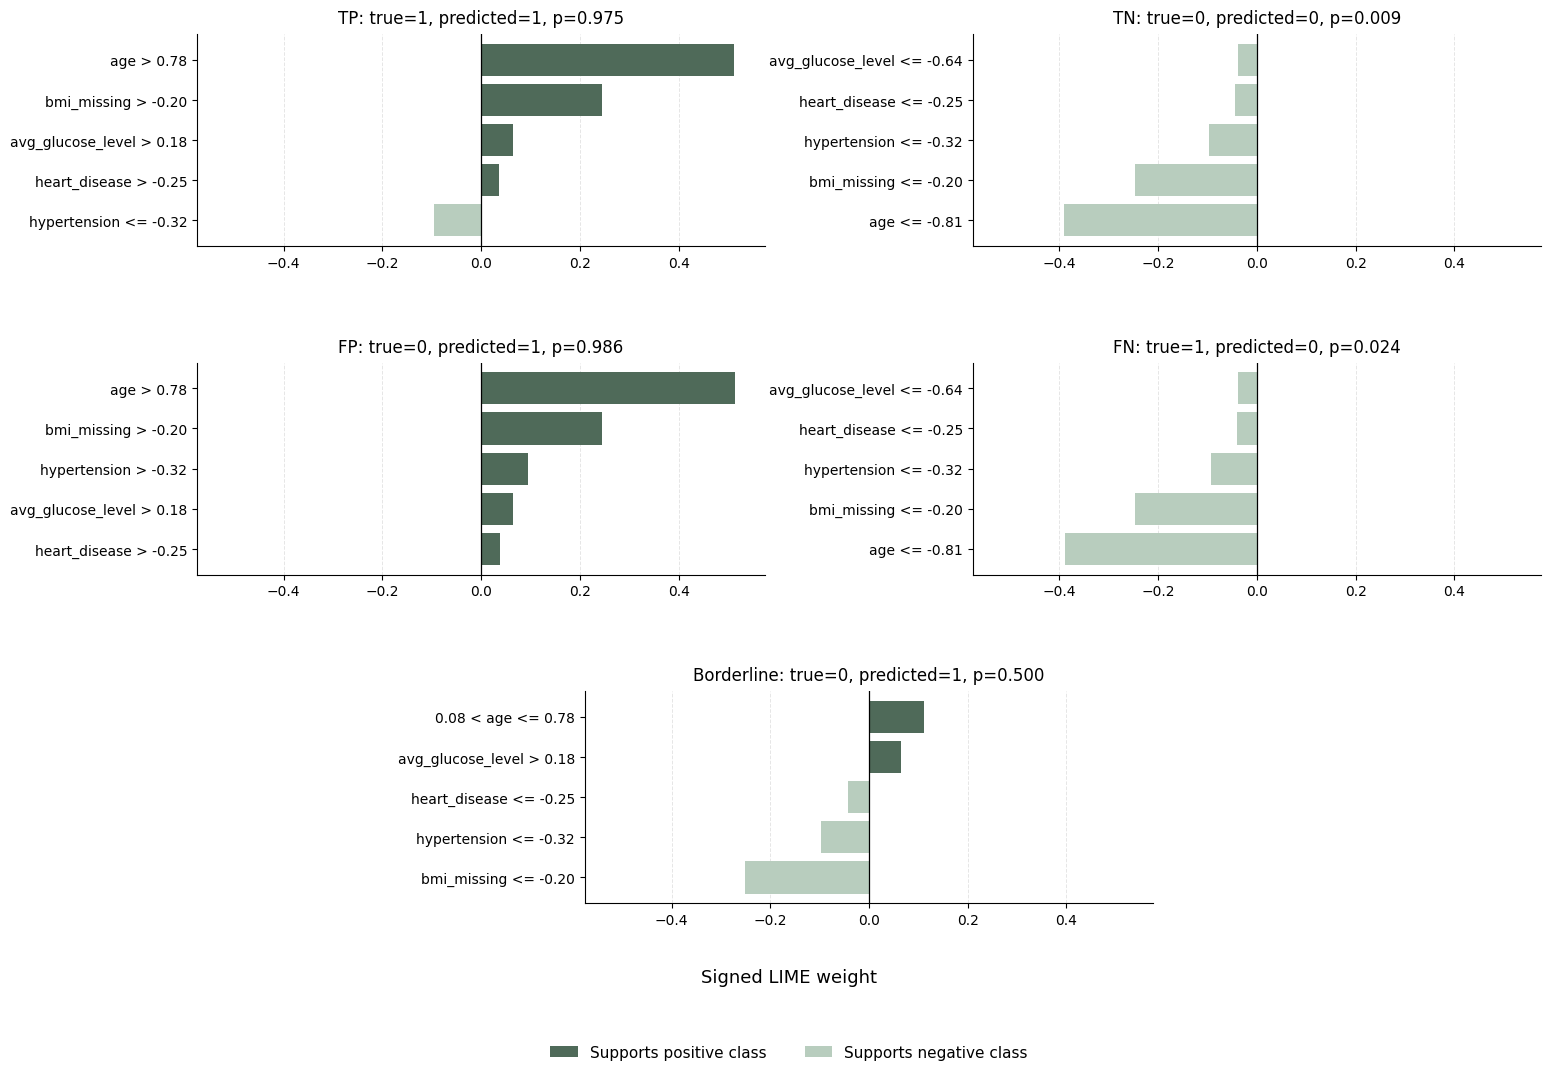

In [24]:

fig = plt.figure(
    figsize=(16, 11)
)

grid = fig.add_gridspec(
    3,
    4,
    hspace=0.55,
    wspace=1.15,
)

axes = [
    fig.add_subplot(grid[0, 0:2]),
    fig.add_subplot(grid[0, 2:4]),
    fig.add_subplot(grid[1, 0:2]),
    fig.add_subplot(grid[1, 2:4]),
    fig.add_subplot(grid[2, 1:3]),
]

positive_color = "#4F6A59"
negative_color = "#B8CDBE"

for ax, case_type in zip(
    axes,
    stroke_case_order,
):
    case_rules = (
        stroke_lime[
            stroke_lime["CaseType"] == case_type
        ]
        .sort_values("Weight")
        .copy()
    )

    metadata = stroke_case_metadata[
        stroke_case_metadata["CaseType"] == case_type
    ].iloc[0]

    labels = [
        fill(str(rule), width=34)
        for rule in case_rules["Rule"]
    ]

    colors = [
        positive_color
        if weight > 0
        else negative_color
        for weight in case_rules["Weight"]
    ]

    ax.barh(
        labels,
        case_rules["Weight"],
        color=colors,
    )

    ax.axvline(
        0,
        color="black",
        linewidth=0.9,
    )

    ax.set_xlim(
        -x_limit,
        x_limit,
    )

    ax.grid(
        axis="x",
        color="#E6E6E6",
        linestyle="--",
        linewidth=0.7,
    )

    ax.set_axisbelow(True)

    ax.set_title(
        f"{case_type}: "
        f"true={int(metadata['True'])}, "
        f"predicted={int(metadata['Predicted'])}, "
        f"p={metadata['Probability']:.3f}",
        fontsize=12,
        pad=8,
    )

    ax.tick_params(
        axis="y",
        labelsize=10,
    )

    ax.tick_params(
        axis="x",
        labelsize=10,
        labelbottom=True,
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.supxlabel(
    "Signed LIME weight",
    fontsize=13,
    y=0.105,
)

fig.legend(
    handles=[
        Patch(
            facecolor=positive_color,
            label="Supports positive class",
        ),
        Patch(
            facecolor=negative_color,
            label="Supports negative class",
        ),
    ],
    loc="lower center",
    bbox_to_anchor=(0.5, 0.025),
    ncol=2,
    frameon=False,
    fontsize=11,
    handlelength=1.8,
    columnspacing=2.5,
)

fig.subplots_adjust(
    left=0.13,
    right=0.97,
    top=0.97,
    bottom=0.18,
    wspace=1.15,
    hspace=0.55,
)

FIGURE_DIR = RESULTS_DIR.parent / "images" / "results"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

figure_path = (
    FIGURE_DIR
    / "stroke_representative_lime.pdf"
)

fig.savefig(
    figure_path,
    bbox_inches="tight",
)

print("Saved:", figure_path)

plt.show()


### 1.5.3 Descriptive explanation strength

Each case type contains at most one deliberately selected representative observation per dataset. The summaries below are case-study descriptions, not inferential comparisons of correct and erroneous predictions.


In [25]:
case_level_strength_df = (
    lime_with_cases_df
    .assign(AbsWeight=lambda x: x["Weight"].abs())
    .groupby(
        ["Dataset", "CaseIndex", "CaseType", "OutcomeGroup"],
        dropna=False
    )
    .agg(
        MeanAbsLIMEWeight=("AbsWeight", "mean"),
        MaxAbsLIMEWeight=("AbsWeight", "max"),
        NRules=("Rule", "count")
    )
    .reset_index()
)

outcome_strength_summary = (
    case_level_strength_df
    .groupby(["Dataset", "OutcomeGroup"], dropna=False)
    .agg(
        MeanCaseAbsLIMEWeight=("MeanAbsLIMEWeight", "mean"),
        MaxCaseAbsLIMEWeight=("MaxAbsLIMEWeight", "max"),
        NCases=("CaseIndex", "nunique")
    )
    .reset_index()
)

display(case_level_strength_df.round(4))
display(outcome_strength_summary.round(4))


,Dataset,CaseIndex,CaseType,OutcomeGroup,MeanAbsLIMEWeight,MaxAbsLIMEWeight,NRules
0,CKD,0,TP,Correct,0.0617,0.0713,5
1,CKD,1,TN,Correct,0.0889,0.0990,5
2,CKD,2,TP,Correct,0.0670,0.0764,5
3,CKD,5,TP,Correct,0.0670,0.0780,5
4,CKD,6,TP,Correct,0.0579,0.0693,5
...,...,...,...,...,...,...,...
207,Stroke,949,FN,Error,0.1025,0.2553,5
208,Stroke,978,FN,Error,0.1211,0.2495,5
209,Stroke,994,FP,Error,0.1916,0.5149,5
210,Stroke,1008,FP,Error,0.1908,0.5142,5


,Dataset,OutcomeGroup,MeanCaseAbsLIMEWeight,MaxCaseAbsLIMEWeight,NCases
0,CKD,Borderline,0.0677,0.0980,10
1,CKD,Correct,0.0716,0.0990,20
2,CKD,Error,0.0689,0.0947,2
3,Diabetes,Borderline,0.0836,0.3762,10
4,Diabetes,Correct,0.1174,0.3785,20
5,Diabetes,Error,0.0861,0.3723,20
6,HbA1c (in-sample),Borderline,0.2677,0.4678,10
7,HbA1c (in-sample),Correct,0.2526,0.4689,10
8,HbA1c (in-sample),Error,0.2504,0.4734,10
9,Heart,Borderline,0.0382,0.0610,10


### 1.5.4 Global-versus-local lexical overlap

This metric reports whether global top-five SHAP terms appear in the five strongest LIME rule strings. It is lexical presence, not formal SHAP–LIME agreement.


In [26]:
def global_top_features(dataset, k=5):
    """Return the leading global features for each method."""
    _, _, shap = load_global_tables(dataset)
    return shap.nlargest(k, "MeanAbsSHAP")["Feature"].tolist()


global_local_rows = []

for dataset in DATASETS:
    dataset_name = DISPLAY_NAMES[dataset]
    global_top = global_top_features(dataset, k=5)
    dataset_lime = lime_with_cases_df[
        lime_with_cases_df["Dataset"] == dataset_name
    ]

    for case_idx, group in dataset_lime.groupby("CaseIndex"):
        strongest = group.nsmallest(5, "Rank")
        lime_text = " ".join(strongest["Rule"].astype(str))
        matched = [
            feature for feature in global_top
            if re.search(
                rf"(?<![A-Za-z0-9_]){re.escape(str(feature))}(?![A-Za-z0-9_])",
                lime_text,
            )
        ]
        global_local_rows.append({
            "Dataset": dataset_name,
            "CaseIndex": case_idx,
            "NGlobalFeatures": len(global_top),
            "NGlobalTop5Matched": len(matched),
            "GlobalLocalOverlap": len(matched) / len(global_top) if global_top else np.nan,
            "MatchedFeatures": ", ".join(matched),
        })

global_local_case_df = pd.DataFrame(global_local_rows).merge(
    case_map_df,
    on=["Dataset", "CaseIndex"],
    how="left",
    validate="one_to_one",
)

display(global_local_case_df.round(3))


,Dataset,CaseIndex,NGlobalFeatures,NGlobalTop5Matched,GlobalLocalOverlap,MatchedFeatures,CaseType,CaseRank
0,Heart,2,5,3,0.6,"cp, exang, thalach",TP,2
1,Heart,4,5,4,0.8,"thal, cp, exang, slope",FN,1
2,Heart,6,5,4,0.8,"thal, cp, exang, thalach",TN,8
3,Heart,7,5,4,0.8,"thal, cp, exang, thalach",FP,4
4,Heart,11,5,4,0.8,"thal, cp, exang, thalach",TP,9
...,...,...,...,...,...,...,...,...
207,HbA1c (in-sample),48396,5,2,0.4,"time_in_hospital, specialty_group[T.Missing or...",TN,1
208,HbA1c (in-sample),48516,5,2,0.4,"time_in_hospital, specialty_group[T.Missing or...",Borderline,6
209,HbA1c (in-sample),55172,5,2,0.4,"time_in_hospital, specialty_group[T.Missing or...",FN,7
210,HbA1c (in-sample),58480,5,2,0.4,"time_in_hospital, specialty_group[T.Missing or...",TN,8


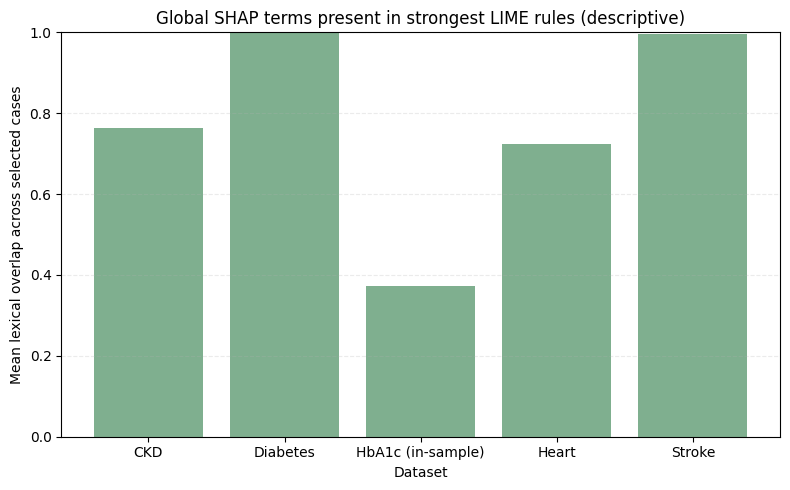

In [27]:
global_local_plot = (
    global_local_case_df.groupby("Dataset", as_index=False)["GlobalLocalOverlap"].mean()
)
plt.figure(figsize=(8, 5))

plt.bar(
    global_local_plot["Dataset"],
    global_local_plot["GlobalLocalOverlap"],
    color="#7FAF8F"
)

plt.ylim(0, 1)

plt.xlabel("Dataset")
plt.ylabel("Mean lexical overlap across selected cases")
plt.title("Global SHAP terms present in strongest LIME rules (descriptive)")

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

plt.tight_layout()
plt.show()


### 1.5.5 Export local XAI tables


In [28]:
local_cases_df.to_csv(
    ANALYSIS_OUT / "representative_cases_all_datasets.csv",
    index=False
)
case_availability.to_csv(
    ANALYSIS_OUT / "local_case_availability.csv",
    index=False
)
lime_seed_stability_df.to_csv(
    ANALYSIS_OUT / "lime_seed_stability_all_datasets.csv",
    index=False
)
lime_repeated_summary_df.to_csv(
    ANALYSIS_OUT / "lime_repeated_summary_all_datasets.csv",
    index=False
)
lime_summary_df.to_csv(
    ANALYSIS_OUT / "lime_summary_all_datasets.csv",
    index=False
)
lime_with_cases_df.to_csv(
    ANALYSIS_OUT / "lime_by_representative_case.csv",
    index=False
)
case_level_strength_df.to_csv(
    ANALYSIS_OUT / "lime_case_strength_summary.csv",
    index=False
)
outcome_strength_summary.to_csv(
    ANALYSIS_OUT / "lime_correct_vs_error_summary.csv",
    index=False
)
global_local_case_df.to_csv(
    ANALYSIS_OUT / "global_local_overlap_by_case.csv",
    index=False
)


In [29]:
case_type_strength_df = (
    case_level_strength_df
    .groupby(
        ["Dataset", "CaseType"],
        as_index=False
    )
    .agg(
        MeanAbsLIMEWeight=("MeanAbsLIMEWeight", "mean")
    )
)

display(case_type_strength_df.round(4))


,Dataset,CaseType,MeanAbsLIMEWeight
0,CKD,Borderline,0.0677
1,CKD,FN,0.0671
2,CKD,FP,0.0708
3,CKD,TN,0.0787
4,CKD,TP,0.0645
5,Diabetes,Borderline,0.0836
6,Diabetes,FN,0.0742
7,Diabetes,FP,0.0981
8,Diabetes,TN,0.1117
9,Diabetes,TP,0.1231


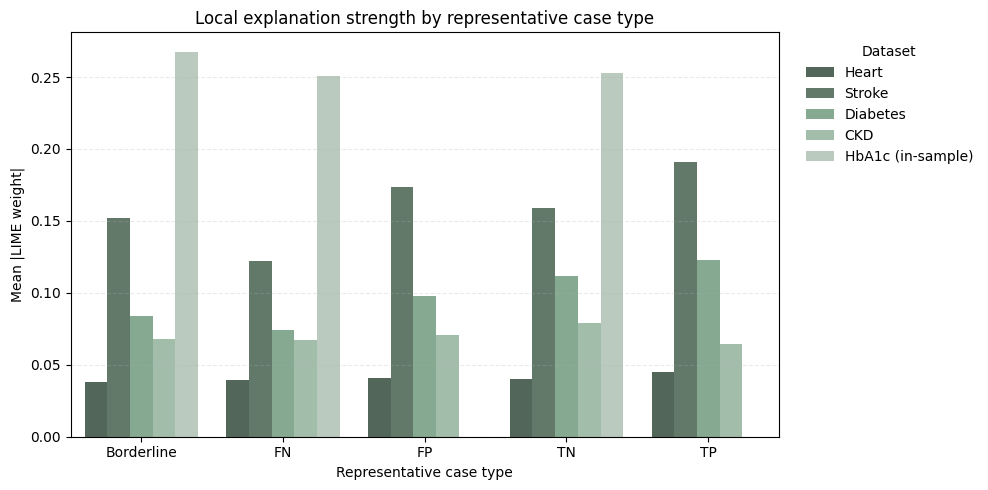

In [30]:
dataset_order = [
    "Heart",
    "Stroke",
    "Diabetes",
    "CKD",
    "HbA1c (in-sample)"
]

plt.figure(figsize=(10, 5))

sns.barplot(
    data=case_type_strength_df,
    x="CaseType",
    y="MeanAbsLIMEWeight",
    hue="Dataset",
    hue_order=dataset_order,
    palette=[
        "#4F6A59",
        "#5E7D68",
        "#7FAF8F",
        "#9FC1AA",
        "#B8CDBE"
    ]
)

plt.xlabel("Representative case type")
plt.ylabel("Mean |LIME weight|")
plt.title("Local explanation strength by representative case type")

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

plt.legend(
    title="Dataset",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

plt.tight_layout()
plt.show()


,Dataset,CaseType,MeanAbsLIMEWeight
0,CKD,Borderline,0.0677
1,CKD,FN,0.0671
2,CKD,FP,0.0708
3,CKD,TN,0.0787
4,CKD,TP,0.0645
5,Diabetes,Borderline,0.0836
6,Diabetes,FN,0.0742
7,Diabetes,FP,0.0981
8,Diabetes,TN,0.1117
9,Diabetes,TP,0.1231


Saved figure to: C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\images\results\lime_case_type_normalized_v2.pdf


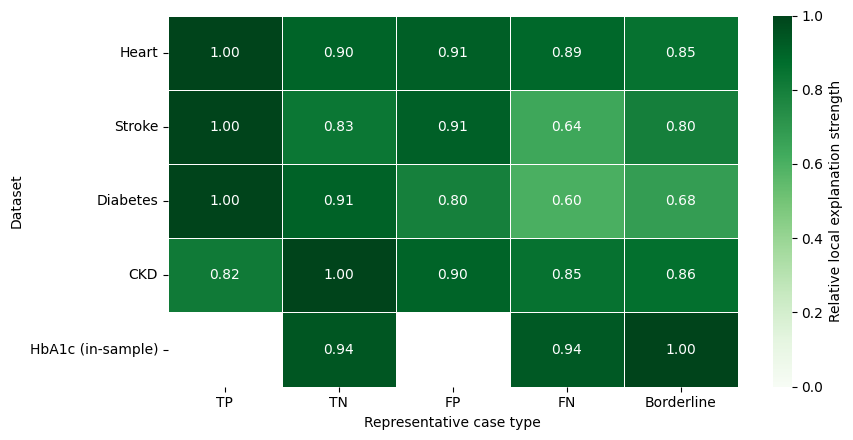

In [31]:
case_type_strength_df = (
    case_level_strength_df
    .groupby(
        ["Dataset", "CaseType"],
        as_index=False,
    )
    .agg(
        MeanAbsLIMEWeight=(
            "MeanAbsLIMEWeight",
            "mean",
        )
    )
)

display(case_type_strength_df.round(4))

lime_heatmap = (
    case_type_strength_df
    .pivot(
        index="Dataset",
        columns="CaseType",
        values="MeanAbsLIMEWeight"
    )
)

# Logical case-type order.
case_order = [
    case_type
    for case_type in ["TP", "TN", "FP", "FN", "Borderline"]
    if case_type in lime_heatmap.columns
]

lime_heatmap = lime_heatmap[case_order]

# Normalise each dataset independently.
row_max = lime_heatmap.max(axis=1).replace(0, np.nan)

lime_heatmap_normalized = lime_heatmap.div(
    row_max,
    axis=0
)

# Use the same dataset order as the rest of the dissertation.
preferred_dataset_order = [
    "Heart",
    "Stroke",
    "Diabetes",
    "CKD",
    "HbA1c",
    "HbA1c (in-sample)"
]

dataset_order = [
    dataset
    for dataset in preferred_dataset_order
    if dataset in lime_heatmap_normalized.index
]


lime_heatmap_normalized = lime_heatmap_normalized.reindex(
    dataset_order
)

plt.figure(figsize=(9, 4.5))

sns.heatmap(
    lime_heatmap_normalized,
    annot=True,
    fmt=".2f",
    cmap="Greens",
    linewidths=0.5,
    vmin=0,
    vmax=1,
    cbar_kws={
        "label": "Relative local explanation strength"
    }
)

plt.xlabel("Representative case type")
plt.ylabel("Dataset")
plt.title(
    ""
)

plt.tight_layout()


figure_dir = Path("../../images/results").resolve()
figure_dir.mkdir(parents=True, exist_ok=True)

figure_path = (
    figure_dir /
    "lime_case_type_normalized_v2.pdf"
)

fig = plt.gcf()

fig.savefig(
    figure_path,
    bbox_inches="tight"
)

print("Saved figure to:", figure_path)

plt.show()


Since raw LIME magnitudes are not necessarily directly comparable across different models/datasets, here we have a within-dataset normalized heatmap.

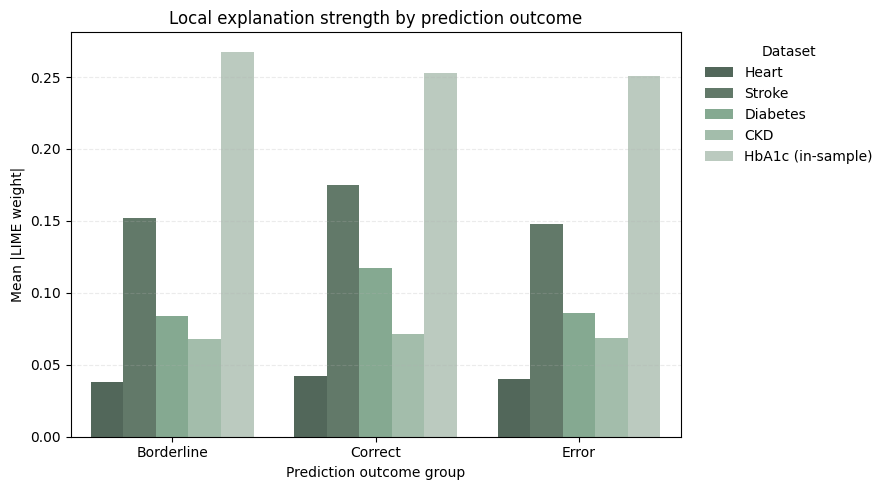

In [32]:
outcome_plot_df = (
    case_level_strength_df
    .groupby(
        ["Dataset", "OutcomeGroup"],
        as_index=False
    )
    .agg(
        MeanAbsLIMEWeight=("MeanAbsLIMEWeight", "mean")
    )
)

dataset_order = [
    "Heart",
    "Stroke",
    "Diabetes",
    "CKD",
    "HbA1c (in-sample)"
]

plt.figure(figsize=(9, 5))

sns.barplot(
    data=outcome_plot_df,
    x="OutcomeGroup",
    y="MeanAbsLIMEWeight",
    hue="Dataset",
    hue_order=dataset_order,
    palette=[
        "#4F6A59",
        "#5E7D68",
        "#7FAF8F",
        "#9FC1AA",
        "#B8CDBE"
    ]
)

plt.xlabel("Prediction outcome group")
plt.ylabel("Mean |LIME weight|")
plt.title("Local explanation strength by prediction outcome")

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

plt.legend(
    title="Dataset",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

plt.tight_layout()
plt.show()


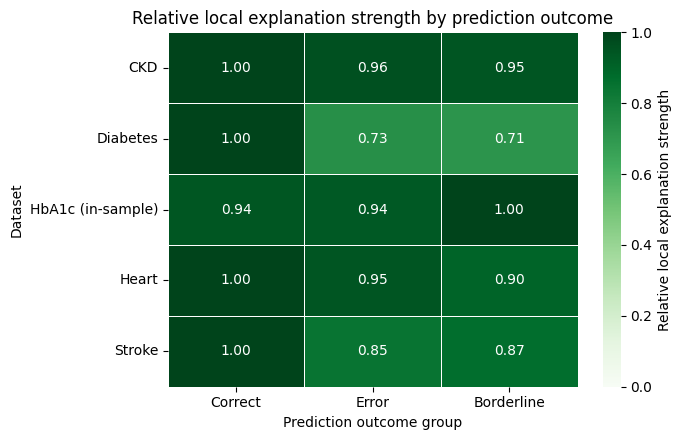

In [33]:
outcome_heatmap = (
    outcome_plot_df
    .pivot(
        index="Dataset",
        columns="OutcomeGroup",
        values="MeanAbsLIMEWeight"
    )
)

outcome_order = [
    c for c in ["Correct", "Error", "Borderline"]
    if c in outcome_heatmap.columns
]

outcome_heatmap = outcome_heatmap[outcome_order]

outcome_heatmap_normalized = (
    outcome_heatmap
    .div(
        outcome_heatmap.max(axis=1).replace(0, np.nan),
        axis=0
    )
)

plt.figure(figsize=(7, 4.5))

sns.heatmap(
    outcome_heatmap_normalized,
    annot=True,
    fmt=".2f",
    cmap="Greens",
    linewidths=0.5,
    vmin=0,
    vmax=1,
    cbar_kws={
        "label": "Relative local explanation strength"
    }
)

plt.xlabel("Prediction outcome group")
plt.ylabel("Dataset")
plt.title(
    "Relative local explanation strength by prediction outcome"
)

plt.tight_layout()
plt.show()


# 1.6 Cross-dataset and model-family comparison

Model-family summaries are descriptive. With two linear datasets, two tree datasets, and one statsmodels dataset, they must not be presented as population-level statistical evidence.


In [34]:
summary_rows = []

for dataset in DATASETS:
    metadata = load_metadata(dataset)
    model_name = metadata.get("model", "Unknown")

    if model_name == "BinaryResultsWrapper":
        model_name = "Statsmodels logistic regression"

    if dataset in ["heart", "stroke"]:
        model_family = "Linear classification"
    elif dataset in ["diabetes", "ckd"]:
        model_family = "Tree ensemble"
    else:
        model_family = "Statsmodels logistic regression"

    ranks = global_rank_table(dataset)
    dataset_agreement = agreement_df[
        agreement_df["Dataset"] == DISPLAY_NAMES[dataset]
    ]
    dataset_stability = stability_summary_df[
        stability_summary_df["Dataset"] == DISPLAY_NAMES[dataset]
    ]

    summary_rows.append({
        "Dataset": DISPLAY_NAMES[dataset],
        "Model": model_name,
        "ModelFamily": model_family,
        "FeaturesCompared": len(ranks),
        "MeanCrossMethodRho": (
            dataset_agreement["SpearmanRho"].mean()
        ),
        "MeanStabilityRho": (
            dataset_stability["MeanStabilityRho"].iloc[0]
        ),
        "MeanTopKOverlap": (
            dataset_stability["MeanTopKOverlap"].iloc[0]
        )
    })

cross_dataset_summary_df = pd.DataFrame(summary_rows)

model_family_summary_df = (
    cross_dataset_summary_df
    .groupby("ModelFamily", dropna=False)
    .agg(
        NDatasets=("Dataset", "nunique"),
        MeanFeaturesCompared=("FeaturesCompared", "mean"),
        MeanCrossMethodRho=("MeanCrossMethodRho", "mean"),
        MeanStabilityRho=("MeanStabilityRho", "mean"),
        MeanTopKOverlap=("MeanTopKOverlap", "mean")
    )
    .reset_index()
)

display(cross_dataset_summary_df.round(3))
display(model_family_summary_df.round(3))

cross_dataset_summary_df.to_csv(
    ANALYSIS_OUT / "xai_summary.csv",
    index=False
)
model_family_summary_df.to_csv(
    ANALYSIS_OUT / "model_family_comparison.csv",
    index=False
)


,Dataset,Model,ModelFamily,FeaturesCompared,MeanCrossMethodRho,MeanStabilityRho,MeanTopKOverlap
0,Heart,LogisticRegressionCV,Linear classification,13,0.738,0.700,0.645
1,Stroke,LogisticRegression,Linear classification,7,0.754,0.812,0.741
2,Diabetes,RandomForestClassifier,Tree ensemble,5,1.000,0.849,0.890
3,CKD,RandomForestClassifier,Tree ensemble,24,0.817,0.949,0.759
4,HbA1c (in-sample),Statsmodels logistic regression,Statsmodels logistic regression,90,0.446,NaN,NaN


,ModelFamily,NDatasets,MeanFeaturesCompared,MeanCrossMethodRho,MeanStabilityRho,MeanTopKOverlap
0,Linear classification,2,10.0,0.746,0.756,0.693
1,Statsmodels logistic regression,1,90.0,0.446,NaN,NaN
2,Tree ensemble,2,14.5,0.908,0.899,0.825


# 1.7 Framework robustness and generalizability

The capability table records what was successfully demonstrated by these five replications. It does not claim support beyond the tested configurations.


Capability flags indicate nonempty exports with the expected columns, not an independent correctness test. Input representations follow the current extension notebook configurations; the bundle metadata does not record the original input container type.

In [35]:
def output_available(dataset, filename, required_columns):
    """Return whether a requested exported output is available."""
    path = RESULTS_DIR / dataset / filename
    if not path.is_file():
        return False
    table = pd.read_csv(path)
    return not table.empty and set(required_columns).issubset(table.columns)

capability_rows = []
for dataset in DATASETS:
    summary = cross_dataset_summary_df.loc[cross_dataset_summary_df["Dataset"] == DISPLAY_NAMES[dataset]].iloc[0]
    capability_rows.append({
        "Dataset": DISPLAY_NAMES[dataset],
        "ModelFamily": summary["ModelFamily"],
        "InputRepresentation": "Patsy design matrix (DataFrame)" if dataset == "hba1c" else "DataFrame",
        "EvaluationScope": "In-sample" if dataset == "hba1c" else "Held-out",
        "NativeImportanceDemonstrated": output_available(dataset, "native_importance.csv", ["Feature", "Importance"]),
        "PermutationDemonstrated": output_available(dataset, "permutation_importance.csv", ["Feature", "Importance"]),
        "SHAPDemonstrated": output_available(dataset, "shap_importance.csv", ["Feature", "MeanAbsSHAP"]),
        "LIMEDemonstrated": output_available(dataset, "lime_explanations.csv", ["CaseIndex", "Rule", "Weight"]),
        "StabilityDemonstrated": dataset != "hba1c" and output_available(dataset, "stability_rank.csv", ["SpearmanRankCorrelation", "TopKOverlap"]),
    })
framework_summary = pd.DataFrame(capability_rows)

framework_limitations = pd.DataFrame([
    {
        "Area": "Prediction task",
        "Limitation": "Evidence is limited to binary classification."
    },
    {
        "Area": "Decision threshold",
        "Limitation": "Representative cases assume the configured binary threshold."
    },
    {
        "Area": "HbA1c stability",
        "Limitation": "No canonical stability result is included; only 58 of 100 exploratory refits converged."
    },
    {
        "Area": "HbA1c representation",
        "Limitation": "Explanations refer to Patsy design terms and interactions, not only raw variables."
    },
    {
        "Area": "Local cases",
        "Limitation": "Selected representative cases are descriptive and are not a population sample."
    },
    {
        "Area": "Method comparison",
        "Limitation": "Importance magnitudes are not directly comparable across XAI methods."
    }
])

display(framework_summary)
display(framework_limitations)

framework_summary.to_csv(
    ANALYSIS_OUT / "framework_capability_summary.csv",
    index=False
)
framework_limitations.to_csv(
    ANALYSIS_OUT / "framework_limitations.csv",
    index=False
)


,Dataset,ModelFamily,InputRepresentation,EvaluationScope,NativeImportanceDemonstrated,PermutationDemonstrated,SHAPDemonstrated,LIMEDemonstrated,StabilityDemonstrated
0,Heart,Linear classification,DataFrame,Held-out,True,True,True,True,True
1,Stroke,Linear classification,DataFrame,Held-out,True,True,True,True,True
2,Diabetes,Tree ensemble,DataFrame,Held-out,True,True,True,True,True
3,CKD,Tree ensemble,DataFrame,Held-out,True,True,True,True,True
4,HbA1c (in-sample),Statsmodels logistic regression,Patsy design matrix (DataFrame),In-sample,True,True,True,True,False


,Area,Limitation
0,Prediction task,Evidence is limited to binary classification.
1,Decision threshold,Representative cases assume the configured bin...
2,HbA1c stability,No canonical stability result is included; onl...
3,HbA1c representation,Explanations refer to Patsy design terms and i...
4,Local cases,Selected representative cases are descriptive ...
5,Method comparison,Importance magnitudes are not directly compara...


In [36]:
print(framework_summary.columns.tolist())
display(framework_summary)


['Dataset', 'ModelFamily', 'InputRepresentation', 'EvaluationScope', 'NativeImportanceDemonstrated', 'PermutationDemonstrated', 'SHAPDemonstrated', 'LIMEDemonstrated', 'StabilityDemonstrated']


,Dataset,ModelFamily,InputRepresentation,EvaluationScope,NativeImportanceDemonstrated,PermutationDemonstrated,SHAPDemonstrated,LIMEDemonstrated,StabilityDemonstrated
0,Heart,Linear classification,DataFrame,Held-out,True,True,True,True,True
1,Stroke,Linear classification,DataFrame,Held-out,True,True,True,True,True
2,Diabetes,Tree ensemble,DataFrame,Held-out,True,True,True,True,True
3,CKD,Tree ensemble,DataFrame,Held-out,True,True,True,True,True
4,HbA1c (in-sample),Statsmodels logistic regression,Patsy design matrix (DataFrame),In-sample,True,True,True,True,False


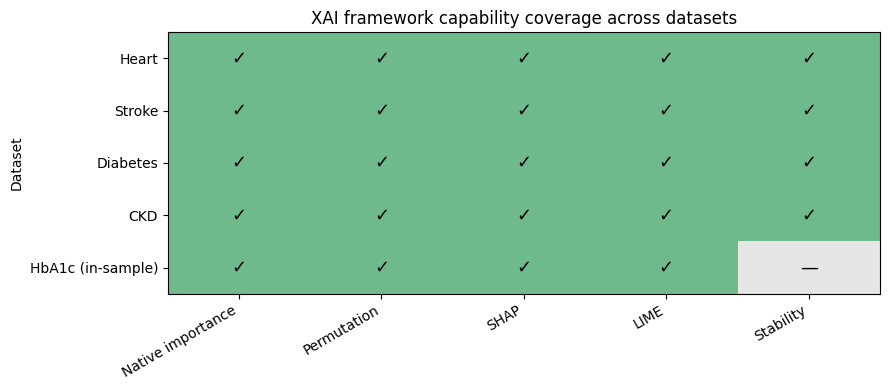

In [37]:
capability_columns = [
    "NativeImportanceDemonstrated",
    "PermutationDemonstrated",
    "SHAPDemonstrated",
    "LIMEDemonstrated",
    "StabilityDemonstrated"
]

capability_labels = [
    "Native importance",
    "Permutation",
    "SHAP",
    "LIME",
    "Stability"
]

capability_matrix = (
    framework_summary
    .set_index("Dataset")[capability_columns]
    .astype(int)
)


cmap = ListedColormap([
    # Not demonstrated.
    "#E6E6E6",
    # Demonstrated.
    "#6FBA8C"
])

fig, ax = plt.subplots(figsize=(9, 4))

ax.imshow(
    capability_matrix.values,
    aspect="auto",
    cmap=cmap,
    vmin=0,
    vmax=1
)

ax.set_xticks(range(len(capability_labels)))
ax.set_xticklabels(
    capability_labels,
    rotation=30,
    ha="right"
)

ax.set_yticks(range(len(capability_matrix.index)))
ax.set_yticklabels(capability_matrix.index)

for i in range(capability_matrix.shape[0]):
    for j in range(capability_matrix.shape[1]):

        value = capability_matrix.iloc[i, j]

        ax.text(
            j,
            i,
            "✓" if value == 1 else "—",
            ha="center",
            va="center",
            fontsize=13,
            color="black"
        )

ax.set_title(
    "XAI framework capability coverage across datasets"
)

ax.set_xlabel("")
ax.set_ylabel("Dataset")

plt.tight_layout()
plt.show()


## Synthesis

The combined analysis shows that predictive performance, agreement among explanation methods, local repeatability, and bootstrap-refit stability are distinct properties. No dataset or model family was uniformly strongest on every criterion. The family-level summaries are descriptive because each family contains at most two datasets, while HbA1c represents a single in-sample Statsmodels configuration. The exported tables support the thesis comparisons but do not establish causal, clinical, or population-level conclusions.
